# Multi-Otsu box, four pad arms: does padding the tightened template help at K = 10? -- 49 ROIs x 6 clicks, post-D11

**Pre-registration.** This cell was written before the full run, from `MULTIOTSU_PAD_ARMS_PROMPT.md`. It fixes the design,
the tests, the flags and the contamination rule. It does not fix the conclusion. Items marked **[gap]** are places where the
prompt was silent or internally inconsistent. Each resolution given here was fixed before the run, and none is less
conservative than the prompt.

## What changes against the window sweep

`refine_template_box` (commit `154863e`) is copied verbatim, with its constants, from cells 3 and 1 of
`multiotsu_template_refinement_14roi.ipynb`. For each click it returns a square box of side
`bs = odd(longer bbox side) + 2 * pad_px`, centred on the selection's bounding box. `pad_px` = 2 on all 49 ROIs, asserted.

Against `window_sweep_51_61_71_49roi_6seed.ipynb`, **two things change**:

1. The kept region is the whole `bs x bs` box, raw pixels, not the recorded Otsu rectangle.
2. Every template is centred on the box centre, not on the click:
   `(tcx, tcy) = (int(round(center_xy[0])), int(round(center_xy[1])))`. It is rounded once, with Python's `round` (half to
   even), which is `read_padded_patch`'s own convention.

**Everything else is the sweep's:**
- the 294 clicks and the `hematoxylin_od` channel;
- the blank, 51 x 51 centred on the click, on every arm;
- `TM_CCOEFF`;
- peak extraction: minimum distance 7, `DEEP_FLOOR_Z` -1.5, `MAX_PEAKS` 100;
- NMS radius = match radius = `ev.radius_px(mpp)` (7.5 um, D7);
- `od`: a 51 px window on the unblanked channel;
- greedy matching, with the click's own annotation removed;
- both ranking axes, K = 10, and the statistics code.

## The four arms

Each template is an `S x S` window of `hematoxylin_od` cut at `(tcx, tcy)`. Its kept region is the central `bs x bs` square,
at `o = (S - bs) // 2`. Every other pixel is set to `np.float32(T[~mask].astype(np.float64).mean())`, computed on that arm's
own window. The dtype, fill and SHA-1 follow the sweep's `build_templates`.

| arm | `S` | template |
|---|---|---|
| `mo_box` | `bs` | the box, raw, no fill |
| `mo_pad51` | 51 | the box padded evenly to 51 x 51, the pad set to its own mean |
| `mo_pad61` | 61 | the same, padded to 61 x 61 |
| `mo_ring5` | `bs + 10` | the box plus a 5 px ring on every side, the ring set to its own mean |

"51 px pad" and "61 px pad" mean a **total template side** of 51 and 61, the sweep's `W`. That makes 4 arms x 294 clicks =
1176 searches, fewer if any click is refused. Each search returns one detection list, and both axes rank it.

**Pipeline, per (click, arm):**
1. Blank the click's 51 px square.
2. Pad the blanked channel by `PAD = (S - 1) // 2`, replicate.
3. Run `fused_response`, crop back, and assert `valid.all()`.
4. Robust threshold, then `extract_peaks(7, threshold, 100)`, then NMS.
5. `od` on the unblanked channel, padded by **25 px on every arm**.
6. Rank per axis (mergesort, NaN last), match, and count TP@K.

## Reference arms, with no extra searches

`default_51`, `fill_51` and `fill_61` are read from `precision_at_k_49roi_6seed_windowsweep_postD11_{per_run,top30}.csv`.
Every join is on `(file_name, seed_index, condition, rank_key)`.

**Parity gate (halts).** Before the loop, `default_51` and `fill_61` are rebuilt exactly as the sweep built them: centred on
the click, with the recorded rectangle shifted into the 61 window. They are searched on `337.tiff` and `509.tiff` (12 clicks,
48 (click, arm, axis) rows) with the sweep's search code, and must match the saved rows on:
- `tp_at_10/20/30`, `n_peaks`, `n_detections`, `n_blanked_px`, `n_kept_px`, `n_filled_px`, `fill_value`, `tpl_sha1`;
- the top 30's `rank, cx, cy, bucket, matched_ann_id`;
- `score` after a float32 cast, and `od` at rtol 1e-12.

**[gap]** The sweep's `search_once` padded the `od` channel by the search `PAD`, but this prompt requires 25 on every arm. So
`search_once` takes one added argument, `od_pad`, and that is its only change. The parity gate calls the same function the
main loop calls, with `od_pad = 25`. `fill_61`, whose search `PAD` is 30, therefore also checks the `od`-pad change. The
bit-exact `od` count is printed.

## Inputs, refusals and the tripwire, all before any search

- **Clicks.** `precision_at_k_49roi_6seed_fillgeom_postD11_clicks.csv`, 294 rows. The bootstrap's ROI order is the order of
  first appearance in `..._fillgeom_postD11_per_run.csv`.
- **Refusals.** `refine_template_box` runs on all 294 clicks first, in smoke mode as well, and every refusal is printed with
  its reason. **More than 15 refusals halt the notebook.** Otherwise:
  - a refused click is dropped from every arm and every reference;
  - a ROI's value sums over its accepted clicks, and the pooled denominator is 10 x the accepted clicks;
  - a ROI with no accepted click leaves, and D5's majority counts the ROIs that remain.
- **Tripwire (halts).** 19 of the clicks are among the method's 24 adoption clicks (`multiotsurefine14_summary.csv`, joined
  on `file_name` and `seed_ann_id` = `ann_id`). On those 19, `accepted`, `base_size_px`, `center_x` and `center_y` must
  match exactly.
- **Also asserted:** `pad_px == 2` everywhere, `bs` odd, and every `S` odd and at most 73.

## Inline asserts (halt)

1. `n_blanked_px == 2601` on every row.
2. On every filled template:
   - `n_filled_px == S*S - bs*bs`;
   - the fill equals `np.float32(raw[~mask].astype(np.float64).mean())`, recomputed from the raw window;
   - the filled pixels equal the fill, and the kept pixels equal the raw window.
3. Every arm's central `bs x bs` square equals the raw `bs x bs` box read at `(tcx, tcy)`, pixel for pixel. `mo_box` equals
   the box exactly.
4. `n_detections >= 10`.

Two more checks:
- The replicate-padded read equals `read_padded_patch` wherever `read_padded_patch` works.
- A `box_ge_S` template has the same SHA as `mo_box`, and its searched top 30 equals `mo_box`'s on both axes.

## Flags: reported, never halting

Each flag is counted per arm, and every flagged click is listed. The offset is
`off = max(|tcx - round(click_cx)|, |tcy - round(click_cy)|)`.

- **`box_outside_blank`**: `off + (bs - 1) // 2 > 25`. It is the same box in every arm, so the same clicks carry it in every
  arm.
- **`template_outside_window`**: `off + (S - 1) // 2 > 25`, using the actual `S`. It is informational, and it fires on
  every `mo_pad61` click by construction (30 > 25).
- **`roi_edge_read`**: `read_padded_patch(hem, tcx, tcy, S)` returns `None`. The window is then cut from the channel
  replicate-padded by 36 px (`tm.PATCH_SIZE // 2`).
- **`box_ge_S`** (`mo_pad51`, `mo_pad61`): `bs >= S`. **[gap]** The template is then the `bs x bs` box, unfilled:
  - it is recorded with `S = bs`, the actual side, which the flags, `PAD` and the reach all use;
  - `S_nominal` = 51 or 61 is kept as well;
  - the fill and the mass weight are NaN;
  - it is searched like any other row and asserted identical to `mo_box`.
- **`mass_weight_nonpositive`**: `m_k - f <= 0`, on filled templates only. `m_k` is the template mean over the kept square
  and `f` is the fill. The minimum mass weight is printed per arm.

**Flag-excluded rerun (descriptive). [gap: definition]**
- It runs for each flag, and for the union of the four non-informational flags.
- Every tested contrast is recomputed at K = 10, excluding every click on which the flag fires in **either** arm of the
  contrast. Reference arms carry no flags.
- A ROI with no click left leaves.
- A contrast with no flagged click is reported as identical to its recorded row.
- A contrast with no click left is reported as "no clicks remain". That is expected for `template_outside_window` in any
  `mo_pad61` contrast.

## Contamination rule, fixed before the run

- **Self-match**: a non-TP detection within 2 px (Chebyshev) of the template centre `(tcx, tcy)` or of the click. It is
  counted per (arm, axis), in the top 10 and in the top 30. **[gap]** It is counted for the three reference arms too, from
  their saved top 30. Their template centre is the click.
- **The rule**: if an arm has any self-match in its top 10 on an axis, every tested contrast containing that arm on that
  axis is **contaminated**.
  - At `tm_score` it is **resolved** only if the self-match-dropped version and the worst-case bound give the same D5 verdict
    as the recorded version. Otherwise it is **unresolved**.
  - At `chromatin_od` it is **unresolved**.
- **Self-match-dropped version**: drop every self-match detection from each top-30 list and take the top 10 again. Each
  dropped detection is asserted to be `non_human_findings` with `matched_ann_id == -1`. If one is not, the notebook halts and
  that is reported.
- **Worst case (`tm_score`)**, following the sweep's post-run logic: to each contaminated arm, add every self-match top-10
  slot as a displaced TP, plus one TP for every other mitosis within `2 r + 3` px, on every accepted click of the ROI. Two
  extensions are pre-registered; neither is less conservative than the prompt.
  - **[gap] The neighbourhood.** The prompt counts mitoses within `2 r + 3` of the click, because the self-match peak lies
    within `2 sqrt(2)` px of it. That holds for a self-match at the click. It does not hold for one at `(tcx, tcy)`, which
    can sit several px away. So both are computed: the literal click-only neighbourhood, and the union of the click's and
    the template centre's neighbourhoods.
  - **[gap] Both arms contaminated.** If a contrast has a contaminated arm on each side, adding TPs to both no longer bounds
    the delta. The bound is then taken at both ends: once added to the minuend's contaminated arms only, and once to the
    subtrahend's only.
  - Resolution at `tm_score` then requires every version to give the same D5 verdict: recorded, dropped, and every worst case
    (click-only and union, at every end).
- **No flag is lifted or overridden here.** A fired rule is reported, and the user decides.

**Near-seed count (a diagnostic, not a rule).** Two counts:
- Non-TP top-10 detections within each click's reach, `25 + (S - 1) // 2 + off`, measured Chebyshev from the rounded click
  (the blank's own centre).
- For comparison with the references, the sweep's fixed 60 px counts, Chebyshev and Euclidean, measured from the float click
  as the sweep measured them. Only `072.tiff` seed 4 has a non-integer click.

**ROI edge.** `tp_at_10_excl_border` uses the sweep's 35 px band. Every detection with `min(cx, cy, w-1-cx, h-1-cy) < 35`
is dropped, identically in every arm, and the rest is re-matched.

## Statistics

The sweep's statistics cell is copied verbatim, including its validation: the fill-geometry run's 10 recorded `delta_stats`
rows must reproduce before any search.

**[gap]** Its `pair_stats` assumes 6 clicks per ROI. Wherever a ROI keeps fewer (after refusals, or in the flag-excluded
reruns), `pair_stats_clicks` is used instead:
- pooled delta `sum d / (k sum n)`;
- bootstrap `sum d[idx] / (k sum n[idx])`;
- t interval over `d_i / (k n_i)`;
- W/L/T, the exact sign-flip p and D5 unchanged.

`pair_stats_clicks` is asserted equal to `pair_stats`, bit for bit, on the 10 validation rows. `pair_stats` itself is used
whenever every ROI keeps all 6 clicks.

**The unit is the ROI.** Per contrast:
- the pooled delta, in points;
- a 95% cluster-bootstrap CI over ROIs (`N_BOOT` 10000, `BOOT_SEED` 20260917);
- a t interval;
- W/L/T and `n_nonzero`;
- an exact sign-flip p and `min_attainable_p`;
- Holm within family;
- D5: the CI excludes 0 **and** a majority of the remaining ROIs move in the delta's direction.

The two axes are two outcomes. They are never pooled.

**Four Holm families, 10 tests, at K = 10:**

| family | tests |
|---|---|
| `tm_score \| pad` | `mo_pad51 - mo_box`, `mo_pad61 - mo_box`, `mo_ring5 - mo_box` |
| `tm_score \| vs_incumbent` | `mo_pad51 - fill_51`, `mo_pad61 - fill_61` |
| `chromatin_od \| pad` | the same three |
| `chromatin_od \| vs_incumbent` | the same two |

`vs_incumbent` moves three things at once: the kept region (the box instead of the recorded Otsu rectangle), the centre (the
box centre instead of the click) and the fill value. A difference there is not attributed to any one of them.

**Descriptive, in no family, supporting no verdict:**
- every arm minus `default_51`: the four arms, plus `fill_51` and `fill_61` for context;
- `mo_pad61 - mo_pad51`, `mo_ring5 - mo_pad51`, `mo_ring5 - mo_pad61`;
- `fill_61 - fill_51` on the accepted clicks;
- the tested contrasts on `tp_at_10_excl_border`, and at K = 20 and K = 30;
- the flag-excluded reruns;
- the self-match-dropped and worst-case versions.

## Figures and outputs

- `mopad_contrasts.png` (no longer in the folder; embedded in the output of cell 27): every K = 10 contrast with its CI. Both axes share one x-axis; tested rows are solid, descriptive
  rows hollow, with W/L/T and Holm.
- `mopad_templates.png` (no longer in the folder; embedded in the output of cell 27): the four templates for 8 clicks, with the click and the blank outline marked. The clicks include
  the smallest and largest `bs`, the largest centre offset, and one click for each flag that fires.
- `../results/precision_at_k_49roi_6seed_mopad_postD11_{templates,per_run,per_roi,delta_per_roi,delta_stats,top30,selfmatch_sensitivity}.csv`:
  - `per_run` and `top30` are rewritten after every ROI;
  - `per_roi` also carries the reference arms, with `source = window sweep`;
  - `delta_stats` carries the flag-excluded reruns under `version`.

`MOPAD_SMOKE_ROIS=337.tiff,509.tiff` runs the identical code and writes `_smoke` outputs: the refusal pass and tripwire on
all 294 clicks, then the parity gate, then the loop on those two ROIs. The recorded run has it unset.

**Not done:**
- no domain analysis;
- no redrawn clicks, and `refine_template_box` is unedited;
- the blank is never moved or resized;
- the references are not re-searched outside the parity gate;
- no K = 20 or K = 30 figure, and no descriptive row, is used in a verdict;
- no flag is lifted.

**Scope caveat.** The 294 clicks were drawn under the old Otsu joint gate, so every click is one that both old Otsu gates
accept.

In [1]:
import gc
import hashlib
import itertools
import math
import os
import sys
import time
from fractions import Fraction

import cv2
import numpy as np
import pandas as pd
from scipy import stats as sps
import matplotlib.pyplot as plt
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops

sys.path.insert(0, '../..')
from midog_utils import channels as ch
from midog_utils import chromatin as cm
from midog_utils import dataset as ds
from midog_utils import evaluate as ev
from midog_utils import invariants as inv
from midog_utils import production as prod
from midog_utils import seed_selection as ss
from midog_utils import template_match as tm
from midog_utils.nms import nms_by_distance

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 80)
pd.set_option('display.max_rows', 400)
pd.set_option('display.max_colwidth', 140)

NB_T0 = time.time()

REFERENCE_CONFIG = dict(CHANNEL='hematoxylin_od', TM_METHOD=cv2.TM_CCOEFF, PEAK_MIN_DISTANCE=7, DEEP_FLOOR_Z=-1.5, MAX_PEAKS=100, OD_WINDOW=51)
CONFIG_DRIFT = pd.DataFrame([dict(setting=k, production_py=getattr(prod, k), reference_notebook=v, match=getattr(prod, k) == v) for k, v in REFERENCE_CONFIG.items()])
print(CONFIG_DRIFT.to_string(index=False))
assert CONFIG_DRIFT['match'].all(), 'midog_utils.production no longer matches the configuration the recorded run used'
assert cv2.TM_CCOEFF == 4, 'TM_METHOD 4 is cv2.TM_CCOEFF'
assert ev.MIDOG_RADIUS_UM == 7.5, 'D7: NMS radius = match radius = 7.5 um'
assert (tm.BASE_SIZE, tm.PATCH_SIZE) == (51, 73), 'the template and patch sizes this notebook hard-codes'
assert hasattr(tm, 'blank_seed_square') and not hasattr(prod, 'SELF_HIT_RADIUS'), 'this is not post-D11 code'
assert set(prod.AXES) == {'tm_score', 'chromatin_od'}, f'production.AXES changed: {prod.AXES}'

# refine_template_box's constants, copied verbatim from cell 1 of multiotsu_template_refinement_14roi.ipynb
WINDOW = tm.BASE_SIZE                                            # 51 px window around the click
CLASSES = 3                                                      # multi-Otsu classes; the top one is kept
DILATE_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))  # 3x3 cross
DILATE_ITERATIONS = 1                                            # 1 px
MIN_PIECE_UM2 = 1.0                                              # speck floor
MIN_BASE_UM = 5.0                                                # base case: the click's piece bbox, longer side
CLICK_RADIUS_UM = 3.75                                           # fallback: piece centre within this of the click
MIN_AREA_UM2 = 3.0                                               # selection must cover at least this
MAX_AREA_FRAC = 0.85                                             # ... and at most this fraction of the window
PAD_UM = 0.5                                                     # margin kept around the selection on every side

SMOKE_ROIS = [s for s in os.environ.get('MOPAD_SMOKE_ROIS', '').split(',') if s] or None   # None = all 49 ROIs
BASE_SIZE = tm.BASE_SIZE       # 51: the od window, and the side of the parity arm default_51
BLANK_SIZE = 51                # the blanked square: 51 x 51, centred on the click, for every arm -- never moved or resized
HALF_BLANK = BLANK_SIZE // 2   # 25
OD_PAD = 25                    # the od channel's replicate pad on every arm, never the search PAD
MAX_SIDE = 2 * (tm.PATCH_SIZE // 2) + 1   # 73: no template side may exceed it
EDGE_READ_PAD = tm.PATCH_SIZE // 2        # 36: the replicate pad a roi_edge_read window is cut from
RING_PX = 5                    # mo_ring5's ring, on every side, whatever bs is
assert WINDOW == BASE_SIZE == BLANK_SIZE and OD_PAD == prod.OD_WINDOW // 2

ARMS = ('mo_box', 'mo_pad51', 'mo_pad61', 'mo_ring5')
ARM_RULE = {'mo_box': 'multi-Otsu box, raw, no fill', 'mo_pad51': 'box kept, padded to 51, pad = mean of the pad', 'mo_pad61': 'box kept, padded to 61, pad = mean of the pad', 'mo_ring5': 'box kept + 5 px ring, ring = mean of the ring'}
PAD_ARMS = ('mo_pad51', 'mo_pad61')        # a fixed total side, so box_ge_S can fire
FILL_ARMS = ('mo_pad51', 'mo_pad61', 'mo_ring5')
REF_ARMS = ('default_51', 'fill_51', 'fill_61')   # read from the window sweep's CSVs; re-searched only in the parity gate
REF_SIDE = {'default_51': 51, 'fill_51': 51, 'fill_61': 61}
ALL_ARMS = ARMS + REF_ARMS
PARITY_ROIS = ('337.tiff', '509.tiff')
PARITY_ARMS = ('default_51', 'fill_61')    # fill_61 exercises the S != 51 padding path
AXES = ('chromatin_od', 'tm_score')
AXIS_KEY = {'chromatin_od': 'od', 'tm_score': 'score'}
assert AXIS_KEY == prod.AXES, f'this notebook and production.AXES disagree: {AXIS_KEY} vs {prod.AXES}'

BUDGETS = (10, 20, 30)         # recorded; only TEST_K is ever tested
TEST_K = 10
SEED_INDICES = (0, 1, 2, 3, 4, 5)
N_CLICKS_PER_ROI = len(SEED_INDICES)
N_BOOT = 10_000
BOOT_SEED = 20260917
MAX_REFUSALS = 15              # 5% of 294: more halts the notebook before any search
NEAR_SEED_PX = 60              # the window sweep's fixed near-seed distance, kept for comparison with the references
EDGE_BAND_PX = 35              # the window sweep's edge band, so tp_at_10_excl_border compares with the references' saved column
SELF_PX = 2                    # a non-TP detection this close (Chebyshev) to the template centre or the click is a self-match
FLAGS = ('box_outside_blank', 'template_outside_window', 'roi_edge_read', 'box_ge_S', 'mass_weight_nonpositive')
INFORMATIONAL_FLAGS = ('template_outside_window',)
EXCLUSION_FLAGS = tuple(f for f in FLAGS if f not in INFORMATIONAL_FLAGS)

# every contrast is a signed sum of arms; the per-ROI value is that sum of click-summed TP counts, an exact integer
CONTRASTS = {
    'mo_pad51 - mo_box': {'mo_pad51': 1, 'mo_box': -1},
    'mo_pad61 - mo_box': {'mo_pad61': 1, 'mo_box': -1},
    'mo_ring5 - mo_box': {'mo_ring5': 1, 'mo_box': -1},
    'mo_pad51 - fill_51': {'mo_pad51': 1, 'fill_51': -1},
    'mo_pad61 - fill_61': {'mo_pad61': 1, 'fill_61': -1},
    'mo_box - default_51': {'mo_box': 1, 'default_51': -1},
    'mo_pad51 - default_51': {'mo_pad51': 1, 'default_51': -1},
    'mo_pad61 - default_51': {'mo_pad61': 1, 'default_51': -1},
    'mo_ring5 - default_51': {'mo_ring5': 1, 'default_51': -1},
    'fill_51 - default_51': {'fill_51': 1, 'default_51': -1},
    'fill_61 - default_51': {'fill_61': 1, 'default_51': -1},
    'mo_pad61 - mo_pad51': {'mo_pad61': 1, 'mo_pad51': -1},
    'mo_ring5 - mo_pad51': {'mo_ring5': 1, 'mo_pad51': -1},
    'mo_ring5 - mo_pad61': {'mo_ring5': 1, 'mo_pad61': -1},
    'fill_61 - fill_51': {'fill_61': 1, 'fill_51': -1},
}
TEST_FAMILY = {'mo_pad51 - mo_box': 'pad', 'mo_pad61 - mo_box': 'pad', 'mo_ring5 - mo_box': 'pad', 'mo_pad51 - fill_51': 'vs_incumbent', 'mo_pad61 - fill_61': 'vs_incumbent'}
FAMILY_SIZE = {'pad': 3, 'vs_incumbent': 2}
TESTED = tuple(TEST_FAMILY)
assert all(sum(c.values()) == 0 and set(c) <= set(ALL_ARMS) for c in CONTRASTS.values()) and set(TESTED) <= set(CONTRASTS), 'a contrast is not a difference of known arms, or a tested contrast is undefined'
assert pd.Series(TEST_FAMILY).value_counts().to_dict() == FAMILY_SIZE and len(TESTED) * len(AXES) == 10, 'the test budget is not 10 tests in 4 families'
METRICS = {'tp_at_10': 10, 'tp_at_10_excl_border': 10, 'tp_at_20': 20, 'tp_at_30': 30}   # only tp_at_10 is tested

SRC = '../../results/precision_at_k_49roi_6seed_fillgeom_postD11'
SWEEP = '../../results/precision_at_k_49roi_6seed_windowsweep_postD11'
ADOPTION_SUMMARY = 'multiotsurefine14_summary.csv'
SUBSET_DIRS = {'original_14': '../../images/extra_valid', 'testing_35': '../../images/extra_valid/testing_set'}
SUFFIX = '' if SMOKE_ROIS is None else '_smoke'
OUT_STEM = f'../../results/precision_at_k_49roi_6seed_mopad_postD11{SUFFIX}'
OUT = {name: f'{OUT_STEM}_{name}.csv' for name in ('templates', 'per_run', 'per_roi', 'delta_per_roi', 'delta_stats', 'top30', 'selfmatch_sensitivity')}
FIG_PATHS = {name: f'mopad_{name}{SUFFIX}.png' for name in ('contrasts', 'templates')}
assert not any(p.startswith(SRC) or p.startswith(SWEEP) for p in OUT.values()) and ADOPTION_SUMMARY not in FIG_PATHS.values(), 'an output path would overwrite an input'

print(f'\narms {ARMS}; references {REF_ARMS} (from {SWEEP}_*.csv); blank {BLANK_SIZE} px at the click for every arm; od pad {OD_PAD}; axes {AXES}; K tested {TEST_K} only')
print(f'tested ({len(TESTED)} per axis, {len(AXES) * len(TESTED)} total): {TESTED}')
print(f'smoke ROIs = {SMOKE_ROIS}')
print('outputs:', *OUT.values(), *FIG_PATHS.values(), sep='\n  ')

          setting  production_py reference_notebook  match
          CHANNEL hematoxylin_od     hematoxylin_od   True
        TM_METHOD              4                  4   True
PEAK_MIN_DISTANCE              7                  7   True
     DEEP_FLOOR_Z           -1.5               -1.5   True
        MAX_PEAKS            100                100   True
        OD_WINDOW             51                 51   True

arms ('mo_box', 'mo_pad51', 'mo_pad61', 'mo_ring5'); references ('default_51', 'fill_51', 'fill_61') (from ../results/precision_at_k_49roi_6seed_windowsweep_postD11_*.csv); blank 51 px at the click for every arm; od pad 25; axes ('chromatin_od', 'tm_score'); K tested 10 only
tested (5 per axis, 10 total): ('mo_pad51 - mo_box', 'mo_pad61 - mo_box', 'mo_ring5 - mo_box', 'mo_pad51 - fill_51', 'mo_pad61 - fill_61')
smoke ROIs = None
outputs:
  ../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv
  ../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv
  ../resul

In [2]:
CLICKS = pd.read_csv(f'{SRC}_clicks.csv', float_precision='round_trip')
REF_RUN = pd.read_csv(f'{SRC}_per_run.csv', float_precision='round_trip')      # the fill-geometry run: the bootstrap ROI order and the statistics validation
REF_STATS = pd.read_csv(f'{SRC}_delta_stats.csv', float_precision='round_trip')
SW_RUN = pd.read_csv(f'{SWEEP}_per_run.csv', float_precision='round_trip')     # the window sweep: the three reference arms
SW_TOP = pd.read_csv(f'{SWEEP}_top30.csv', float_precision='round_trip')
SW_STATS = pd.read_csv(f'{SWEEP}_delta_stats.csv', float_precision='round_trip')
ADOPT = pd.read_csv(ADOPTION_SUMMARY, float_precision='round_trip')            # the method's 24 adoption clicks, for the tripwire
assert (len(CLICKS), len(REF_RUN), len(REF_STATS), len(SW_RUN), len(SW_TOP), len(ADOPT)) == (294, 2352, 10, 4116, 123480, 24), 'a recorded input does not have its expected row count'
assert not CLICKS.duplicated(['file_name', 'seed_index']).any() and CLICKS.groupby('file_name')['seed_index'].apply(lambda v: tuple(sorted(v)) == SEED_INDICES).all(), 'the clicks CSV is not 6 distinct seeds per ROI'
for c in ('rect_y0', 'rect_y1', 'rect_x0', 'rect_x1'):
    assert CLICKS[c].between(0, BASE_SIZE).all(), f'{c} leaves the 51 px frame'
assert ((CLICKS['rect_y1'] > CLICKS['rect_y0']) & (CLICKS['rect_x1'] > CLICKS['rect_x0'])).all() and (CLICKS['rect_h'] == CLICKS['rect_y1'] - CLICKS['rect_y0']).all() and (CLICKS['rect_w'] == CLICKS['rect_x1'] - CLICKS['rect_x0']).all(), 'a recorded rectangle is empty or inconsistent'
CLICKS['click_ix'] = [int(round(v)) for v in CLICKS['click_cx']]   # the rounded click: the blank's own centre (blank_seed_square rounds the same way)
CLICKS['click_iy'] = [int(round(v)) for v in CLICKS['click_cy']]
print(f"clicks not on an integer pixel: {CLICKS.loc[(CLICKS['click_cx'] != CLICKS['click_ix']) | (CLICKS['click_cy'] != CLICKS['click_iy']), ['file_name', 'seed_index', 'click_cx', 'click_cy', 'click_ix', 'click_iy']].to_dict('records')}")

ROI_ORDER_ALL = list(pd.unique(REF_RUN['file_name']))   # the bootstrap's ROI order: the recorded CIs reproduce only in this order
assert len(ROI_ORDER_ALL) == 49 and set(ROI_ORDER_ALL) == set(CLICKS['file_name']), 'the recorded run is not the 49 ROIs of the clicks CSV'
ROI_ORDER = ROI_ORDER_ALL if SMOKE_ROIS is None else [f for f in ROI_ORDER_ALL if f in SMOKE_ROIS]
assert SMOKE_ROIS is None or sorted(ROI_ORDER) == sorted(SMOKE_ROIS), f'smoke ROIs not found: {SMOKE_ROIS}'
assert all(f in ROI_ORDER_ALL for f in PARITY_ROIS)
N_ROIS = len(ROI_ORDER)

# the reference arms, keyed with rank_key so the two axes cannot duplicate
LIST_KEY = ['file_name', 'seed_index', 'condition', 'rank_key']
SW_REF_RUN = SW_RUN[SW_RUN['condition'].isin(REF_ARMS)].copy()
SW_REF_TOP = SW_TOP[SW_TOP['condition'].isin(REF_ARMS)].copy()
assert len(SW_REF_RUN) == 294 * len(REF_ARMS) * len(AXES) and not SW_REF_RUN.duplicated(LIST_KEY).any() and len(SW_REF_TOP) == 30 * len(SW_REF_RUN), 'a reference is not one row and one top-30 list per (click, axis)'
SW_RUN_IX = SW_REF_RUN.set_index(LIST_KEY).sort_index()
SW_TOP_IX = {key: g.sort_values('rank') for key, g in SW_REF_TOP.groupby(LIST_KEY)}
assert len(SW_TOP_IX) == len(SW_RUN_IX) and all(len(g) == 30 and (g['rank'].to_numpy() == np.arange(30)).all() for g in SW_TOP_IX.values()), 'a saved reference top-30 list is not ranks 0..29'
chk = SW_REF_RUN.merge(CLICKS[['file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy']], on=['file_name', 'seed_index'], suffixes=('', '_clk'), validate='many_to_one')
assert (chk['seed_ann_id'] == chk['seed_ann_id_clk']).all() and (chk['click_cx'] == chk['click_cx_clk']).all() and (chk['click_cy'] == chk['click_cy_clk']).all(), 'the sweep rows are not on the clicks CSV clicks'
assert (SW_RUN_IX['n_blanked_px'] == BLANK_SIZE ** 2).all() and (SW_RUN_IX['W'].to_numpy() == [REF_SIDE[c] for c in SW_RUN_IX.index.get_level_values('condition')]).all()

images, annotations = ds.load_annotations('../../databases/MIDOG++.json')
ROI_SIZE = images.set_index('file_name')[['width', 'height']]
MITOSES = annotations.loc[annotations['category_id'] == ds.MITOTIC, ['file_name', 'ann_id', 'cx', 'cy']]

# the references' own diagnostic baselines over all 294 clicks, recomputed from the saved sweep top 30 so every quoted number is printed here
rt = SW_REF_TOP.merge(CLICKS[['file_name', 'seed_index', 'click_cx', 'click_cy', 'click_ix', 'click_iy']], on=['file_name', 'seed_index'], validate='many_to_one')
rt_not_tp = rt['bucket'] != ev.HUMAN_CORRECT_LABEL
rt_cheb = np.maximum((rt['cx'] - rt['click_cx']).abs(), (rt['cy'] - rt['click_cy']).abs())
rt_cheb_round = np.maximum((rt['cx'] - rt['click_ix']).abs(), (rt['cy'] - rt['click_iy']).abs())
rt_reach = HALF_BLANK + (rt['condition'].map(REF_SIDE) - 1) // 2
rt = rt.assign(self_match=(rt_cheb <= SELF_PX) & rt_not_tp, fp_60_cheb=(rt_cheb <= NEAR_SEED_PX) & rt_not_tp, fp_reach=(rt_cheb_round <= rt_reach) & rt_not_tp, top10=rt['rank'] < TEST_K)
REF_BASELINE = rt.groupby(['rank_key', 'condition']).apply(lambda g: pd.Series(dict(selfmatch_top10=int((g['self_match'] & g['top10']).sum()), selfmatch_top30=int(g['self_match'].sum()), near_seed_fp_top10_60cheb=int((g['fp_60_cheb'] & g['top10']).sum()), near_seed_fp_top10_reach=int((g['fp_reach'] & g['top10']).sum()), reach_px=int(rt_reach[g.index].iat[0]))))
print('\nreference arms over all 294 clicks, from the saved window-sweep top 30 (their template centre is the click):')
print(REF_BASELINE.to_string())
saved_60 = SW_REF_RUN.groupby(['rank_key', 'condition'])['n_near_seed_fp_top10_cheb'].sum()
assert (saved_60.reindex(REF_BASELINE.index) == REF_BASELINE['near_seed_fp_top10_60cheb']).all(), 'the recomputed 60 px near-seed count does not match the sweep per_run column'
print(f'\n{N_ROIS} ROIs x {N_CLICKS_PER_ROI} clicks x {len(ARMS)} arms = {N_ROIS * N_CLICKS_PER_ROI * len(ARMS)} searches before refusals')

clicks not on an integer pixel: [{'file_name': '072.tiff', 'seed_index': 4, 'click_cx': 2991.5, 'click_cy': 667.5, 'click_ix': 2992, 'click_iy': 668}]



reference arms over all 294 clicks, from the saved window-sweep top 30 (their template centre is the click):
                         selfmatch_top10  selfmatch_top30  near_seed_fp_top10_60cheb  near_seed_fp_top10_reach  reach_px
rank_key     condition                                                                                                  
chromatin_od default_51                0                0                          0                         0        50
             fill_51                   0                0                          0                         0        50
             fill_61                   0                0                          0                         0        55
tm_score     default_51                0                0                          0                         0        50
             fill_51                   0                0                          0                         0        50
             fill_61                   0   

/var/folders/bd/s3q0hl891vndldy0hx668q0h0000gn/T/ipykernel_17078/1166364074.py:47: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  REF_BASELINE = rt.groupby(['rank_key', 'condition']).apply(lambda g: pd.Series(dict(selfmatch_top10=int((g['self_match'] & g['top10']).sum()), selfmatch_top30=int(g['self_match'].sum()), near_seed_fp_top10_60cheb=int((g['fp_60_cheb'] & g['top10']).sum()), near_seed_fp_top10_reach=int((g['fp_reach'] & g['top10']).sum()), reach_px=int(rt_reach[g.index].iat[0]))))


## The adopted method, verbatim

`refine_template_box` is copied verbatim from cell 3 of `multiotsu_template_refinement_14roi.ipynb`, with its constants from
that notebook's cell 1 (in the configuration cell above). It is not edited, so its docstring and its one wrapped `dict(...)`
call keep that notebook's formatting rather than this one's.

In [3]:
def refine_template_box(hem_img, cx, cy, mpp):
    """
        Find the mitotic figure's chromatin around a click and return the template box.
        hem_img (np.ndarray): the full-ROI hematoxylin_od channel.
        cx, cy (float): click position in ROI pixel coordinates.
        mpp (float): this ROI's microns per pixel.
        Returns dict: accepted (bool), reason (str), base_size (int, template side in px), center_xy (ROI x, y of the template centre, on the selection's bounding box), plus intermediates for plotting.
    """
    hem_patch = tm.read_padded_patch(hem_img, cx, cy, WINDOW)
    result = dict(accepted=False, reason='too close to the ROI border to read the window', base_size=None, center_xy=None,
                  hem_patch=hem_patch, thresholds=None, class_map=None, labels=None, pieces=[], mode=None,
                  selected=[], selection_mask=None, bbox=None, radius_px=CLICK_RADIUS_UM / mpp, pad_px=int(round(PAD_UM / mpp)))
    if hem_patch is None:
        return result

    patch = hem_patch.astype(np.float64)
    py, px = patch.shape[0] // 2, patch.shape[1] // 2
    thresholds = threshold_multiotsu(patch, classes=CLASSES)
    top_class = cv2.dilate((patch > thresholds[-1]).astype(np.uint8), DILATE_KERNEL, iterations=DILATE_ITERATIONS) > 0
    labels = label(top_class, connectivity=1)
    result.update(thresholds=[float(t) for t in thresholds], class_map=np.digitize(patch, thresholds), labels=labels)

    pieces = []
    for r in regionprops(labels):
        ys, xs = r.coords[:, 0], r.coords[:, 1]
        y0, x0, y1, x1 = r.bbox
        pieces.append(dict(label=int(r.label), area_um2=r.area * mpp ** 2, centre_um=float(np.hypot(ys.mean() - py, xs.mean() - px)) * mpp,
                           bbox_um=max(y1 - y0, x1 - x0) * mpp, centre_yx=(float(ys.mean()), float(xs.mean())), speck=r.area * mpp ** 2 < MIN_PIECE_UM2))
    result['pieces'] = pieces
    by_label = {p['label']: p for p in pieces}

    clicked = int(labels[py, px])
    if clicked and not by_label[clicked]['speck'] and by_label[clicked]['bbox_um'] >= MIN_BASE_UM:
        result['mode'] = 'base'
        selected = [clicked]
    else:
        result['mode'] = 'fallback'
        selected = [p['label'] for p in pieces if not p['speck'] and p['centre_um'] <= CLICK_RADIUS_UM]
    for p in pieces:
        p['selected'] = p['label'] in selected
    result['selected'] = selected
    if not selected:
        result['reason'] = f'no piece centre within {CLICK_RADIUS_UM}um of the click'
        return result

    mask = np.isin(labels, selected)
    result['selection_mask'] = mask
    if mask.sum() * mpp ** 2 < MIN_AREA_UM2:
        result['reason'] = f'selection {mask.sum() * mpp ** 2:.2f}um^2 < {MIN_AREA_UM2}um^2'
        return result
    if mask.sum() > MAX_AREA_FRAC * patch.size:
        result['reason'] = f'selection covers more than {MAX_AREA_FRAC:.0%} of the window'
        return result

    ys, xs = np.where(mask)
    y0, y1, x0, x1 = int(ys.min()), int(ys.max()) + 1, int(xs.min()), int(xs.max()) + 1
    half = WINDOW // 2
    ix, iy = int(round(cx)), int(round(cy))
    result.update(accepted=True, reason='accepted', bbox=(y0, y1, x0, x1), base_size=ss._odd(max(y1 - y0, x1 - x0), minimum=5) + 2 * result['pad_px'],
                  center_xy=(ix - half + (x0 + x1 - 1) / 2.0, iy - half + (y0 + y1 - 1) / 2.0))
    return result


print('refine_template_box defined')

refine_template_box defined


## Refusals and the tripwire, before any search

`refine_template_box` runs on all 294 clicks, smoke run or not. More than 15 refusals halt here. The 19 clicks shared with
the method's 24 adoption clicks must reproduce `accepted`, `base_size_px`, `center_x` and `center_y` exactly.

In [4]:
# the refusal pass: refine_template_box on all 294 clicks, before any search, smoke run or not
box_rows = []
t_box = time.time()
for file_name in ROI_ORDER_ALL:
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    assert os.path.exists(path), f'{path} does not exist'
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    for r in rows.itertuples():
        cx, cy = float(r.click_cx), float(r.click_cy)
        res = refine_template_box(hem, cx, cy, mpp)
        acc = bool(res['accepted'])
        rec = dict(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=int(r.seed_index), seed_ann_id=int(r.seed_ann_id), click_cx=cx, click_cy=cy, click_ix=int(r.click_ix), click_iy=int(r.click_iy), mpp=mpp, accepted=acc, refusal_reason='' if acc else res['reason'], mode=res['mode'], n_pieces=len(res['selected']), pad_px=res['pad_px'])
        if acc:
            tcx, tcy = int(round(res['center_xy'][0])), int(round(res['center_xy'][1]))   # rounded once, read_padded_patch's convention
            rec.update(bs=int(res['base_size']), center_x=float(res['center_xy'][0]), center_y=float(res['center_xy'][1]), tcx=tcx, tcy=tcy, offset_px=float(np.hypot(res['center_xy'][0] - cx, res['center_xy'][1] - cy)), offset_cheb_px=max(abs(tcx - int(r.click_ix)), abs(tcy - int(r.click_iy))))
        box_rows.append(rec)
    del hem
    gc.collect()
BOX = pd.DataFrame(box_rows)
for c in ('bs', 'tcx', 'tcy', 'offset_cheb_px'):
    BOX[c] = BOX[c].astype('Int64') if c in BOX else pd.array([pd.NA] * len(BOX), dtype='Int64')
N_REFUSED = int((~BOX['accepted']).sum())
print(f'refine_template_box on all {len(BOX)} clicks in {(time.time() - t_box) / 60:.1f} min: {len(BOX) - N_REFUSED} accepted, {N_REFUSED} refused')
if N_REFUSED:
    print('refused clicks and their reasons:')
    print(BOX.loc[~BOX['accepted'], ['file_name', 'seed_index', 'seed_ann_id', 'domain', 'mode', 'refusal_reason']].to_string(index=False))
assert N_REFUSED <= MAX_REFUSALS, f'{N_REFUSED} refusals exceed {MAX_REFUSALS} (5%): stop before searching and report'

A = BOX[BOX['accepted']]
assert (BOX['pad_px'] == 2).all(), f"pad_px is not 2 on every ROI: {sorted(BOX['pad_px'].unique())}"
assert (A['bs'] % 2 == 1).all() and (A['bs'] + 2 * RING_PX <= MAX_SIDE).all() and max(61, 51) <= MAX_SIDE, 'a box side is even, or a template side would exceed 73'
print(f"\nbox side bs over {len(A)} accepted clicks: min {A['bs'].min()}, median {A['bs'].median():.0f}, max {A['bs'].max()}; bs >= 51 on {int((A['bs'] >= 51).sum())}; mode {A['mode'].value_counts().to_dict()}")
print(f"centre offset (box centre vs click): Euclidean median {A['offset_px'].median():.2f} px, max {A['offset_px'].max():.2f}; Chebyshev (rounded) distribution {A['offset_cheb_px'].value_counts().sort_index().to_dict()}")

# the tripwire: the 19 clicks that are among the method's 24 adoption clicks must reproduce the adoption run exactly
trip = BOX.merge(ADOPT, left_on=['file_name', 'seed_ann_id'], right_on=['file_name', 'ann_id'], suffixes=('', '_adopt'), validate='one_to_one')
assert len(trip) == 19, f'{len(trip)} clicks overlap the adoption set, not 19'
trip['match'] = (trip['accepted'] == trip['accepted_adopt']) & (trip['bs'].astype(float) == trip['base_size_px'].astype(float)) & (trip['center_x'] == trip['center_x_adopt']) & (trip['center_y'] == trip['center_y_adopt'])
print(f'\ntripwire -- the {len(trip)} clicks shared with the adoption run (accepted, base_size_px, center_x, center_y must match exactly):')
print(trip[['file_name', 'seed_index', 'seed_ann_id', 'accepted', 'accepted_adopt', 'bs', 'base_size_px', 'center_x', 'center_x_adopt', 'center_y', 'center_y_adopt', 'mode', 'mode_adopt', 'match']].to_string(index=False))
assert trip['match'].all(), f"tripwire: {int((~trip['match']).sum())} of {len(trip)} adoption clicks do not reproduce -- the method or its inputs changed"
print(f"tripwire passed: {len(trip)}/{len(trip)} reproduce exactly (mode agrees on {int((trip['mode'] == trip['mode_adopt']).sum())}/{len(trip)})")

ACC = A.set_index(['file_name', 'seed_index']).sort_index()
ACCEPTED_SEEDS = {fn: sorted(int(s) for s in A.loc[A['file_name'] == fn, 'seed_index']) for fn in ROI_ORDER}
N_ACCEPTED = sum(len(v) for v in ACCEPTED_SEEDS.values())
print(f'\nthis run: {N_ROIS} ROIs, {N_ACCEPTED} accepted clicks x {len(ARMS)} arms = {N_ACCEPTED * len(ARMS)} searches; ROIs with no accepted click: {[f for f, v in ACCEPTED_SEEDS.items() if not v]}')

refine_template_box on all 294 clicks in 4.1 min: 294 accepted, 0 refused

box side bs over 294 accepted clicks: min 23, median 33, max 55; bs >= 51 on 6; mode {'base': 259, 'fallback': 35}
centre offset (box centre vs click): Euclidean median 2.50 px, max 9.66; Chebyshev (rounded) distribution {0: 18, 1: 66, 2: 82, 3: 57, 4: 39, 5: 13, 6: 8, 7: 8, 8: 1, 9: 2}

tripwire -- the 19 clicks shared with the adoption run (accepted, base_size_px, center_x, center_y must match exactly):
file_name  seed_index  seed_ann_id  accepted  accepted_adopt  bs  base_size_px  center_x  center_x_adopt  center_y  center_y_adopt     mode mode_adopt  match
 300.tiff           0        14499      True            True  29            29    1411.5          1411.5    3555.0          3555.0     base       base   True
 301.tiff           0        14969      True            True  37            37    5910.0          5910.0    3553.5          3553.5     base       base   True
 201.tiff           0         4457      Tr

## Statistics, validated before any search runs

The window sweep's statistics cell, verbatim. Before a single search, it recomputes the fill-geometry run's 10 recorded
`delta_stats` rows from its per-run CSV and must match every column. The next cell adds `pair_stats_clicks` for ROIs that
keep fewer than 6 clicks, and asserts that it equals `pair_stats` bit for bit when every ROI keeps 6.

In [5]:
def sign_flip_null_counts(abs_deltas):
    """
        Exact null distribution of sum(+/-|d_i|) by convolution over integer offsets.

        abs_deltas (array-like): nonzero absolute integer deltas, one per ROI.

        Returns np.ndarray: int64 counts of each sum -T..T (index = sum + T, T = sum |d_i|), totalling 2 ** n.
    """
    d = [int(v) for v in abs_deltas]
    assert all(v > 0 for v in d) and len(d) <= 62, 'nonzero integer deltas only, and 2 ** n must fit int64'
    total = sum(d)
    counts = np.zeros(2 * total + 1, dtype=np.int64)
    counts[total] = 1
    for v in d:
        shifted = np.zeros_like(counts)
        shifted[v:] += counts[:len(counts) - v]
        shifted[:len(counts) - v] += counts[v:]
        counts = shifted
    return counts


def exact_sign_flip_p(deltas):
    """
        Two-sided exact sign-flip p on integer per-ROI deltas, by dynamic-programming convolution.

        deltas (array-like): one integer delta per ROI; zeros carry no sign.

        Returns tuple[float, int]: the p-value and the number of nonzero deltas.
    """
    d = np.asarray(deltas)
    assert np.all(d == np.round(d)), 'the convolution needs integer deltas'
    d = d.astype(np.int64)
    nz = np.abs(d[d != 0])
    if len(nz) == 0:
        return 1.0, 0
    counts = sign_flip_null_counts(nz)
    total = int(nz.sum())
    observed = abs(int(d.sum()))
    sums = np.arange(-total, total + 1)
    return float(Fraction(int(counts[np.abs(sums) >= observed].sum()), 2 ** len(nz))), len(nz)


def brute_force_sign_flip_p(deltas):
    """
        Two-sided sign-flip p by enumerating every sign pattern -- kept only to validate the convolution.

        deltas (array-like): one delta per ROI; zeros carry no sign and are dropped.

        Returns float: the p-value.
    """
    d = np.asarray(deltas, dtype=np.float64)
    nz = np.abs(d[np.abs(d) > 1e-12])
    if len(nz) == 0:
        return 1.0
    signs = np.array(list(itertools.product([1.0, -1.0], repeat=len(nz))))
    return float((np.abs(signs @ nz) >= abs(float(d.sum())) - 1e-9).mean())


def holm_adjust(pvalues):
    """
        Holm step-down adjusted p-values, valid under any dependence between the tests.

        pvalues (array-like): raw p-values of one family of tests.

        Returns np.ndarray: adjusted p-values, in the input order.
    """
    p = np.asarray(pvalues, dtype=float)
    order = np.argsort(p, kind='stable')
    adjusted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order]).clip(max=1.0)
    out = np.empty_like(adjusted)
    out[order] = adjusted
    return out


def boot_index(n_roi, stream=0):
    """
        The cluster-bootstrap resample of ROI indices, seeded exactly as every earlier run seeds it.

        n_roi (int): the number of ROIs being resampled.
        stream (int): 0 for the reported CI; 1.. for the re-seeding stability check.

        Returns np.ndarray: (N_BOOT, n_roi) resampled ROI indices.
    """
    return np.random.default_rng([BOOT_SEED, stream]).integers(n_roi, size=(N_BOOT, n_roi))


def boot_ci_exact(int_values, idx, denominator):
    """
        Percentile 95% CI of a pooled ratio over resampled ROIs, from exact integer numerators.

        int_values (np.ndarray): one integer numerator per ROI.
        idx (np.ndarray): (n_boot, n_roi) resampled ROI indices.
        denominator (int): the pooled denominator per resample.

        Returns tuple[float, float, float, float]: CI low, CI high, and the share of resamples at or above 0 and at or below 0.
    """
    sums = np.asarray(int_values, dtype=np.int64)[idx].sum(axis=1)
    lo, hi = np.percentile(sums / denominator, [2.5, 97.5])
    return float(lo), float(hi), float((sums >= 0).mean()), float((sums <= 0).mean())


def pair_stats(d, k, idx):
    """
        Every statistic for one contrast at one budget, from its per-ROI click-summed integer deltas.

        d (np.ndarray): one integer delta per ROI, in ROI order.
        k (int): the budget K the deltas count true positives in.
        idx (np.ndarray): (N_BOOT, len(d)) bootstrap ROI indices.

        Returns dict: one delta_stats row without its Holm columns.
    """
    d = np.asarray(d, dtype=np.int64)
    n_roi = len(d)
    denominator = N_CLICKS_PER_ROI * n_roi * k
    pooled = d.sum() / denominator
    wins, losses, ties = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    exact_p, n_nonzero = exact_sign_flip_p(d)
    ci_low, ci_high, share_ge_0, share_le_0 = boot_ci_exact(d, idx, denominator)
    x = d / (N_CLICKS_PER_ROI * k)
    half = sps.t.ppf(0.975, n_roi - 1) * x.std(ddof=1) / math.sqrt(n_roi) if n_roi > 1 else np.nan
    t_ci_low, t_ci_high = float(x.mean() - half), float(x.mean() + half)
    ci_excludes_0 = bool(ci_low > 0 or ci_high < 0)
    n_same_direction = wins if pooled > 0 else (losses if pooled < 0 else 0)
    majority = bool(n_same_direction > n_roi / 2)
    return dict(n_roi=n_roi, n_clicks=N_CLICKS_PER_ROI * n_roi, pooled_delta_precision=pooled, wins=wins, losses=losses, ties=ties, n_nonzero=n_nonzero, exact_p=exact_p, min_attainable_p=2.0 ** (1 - n_nonzero) if n_nonzero else 1.0, ci_low=ci_low, ci_high=ci_high, boot_share_ge_0=share_ge_0, boot_share_le_0=share_le_0, t_ci_low=t_ci_low, t_ci_high=t_ci_high, ci_excludes_0=ci_excludes_0, t_ci_excludes_0=bool(t_ci_low > 0 or t_ci_high < 0), n_same_direction=n_same_direction, majority_of_all_rois=majority, d5_bar_met=bool(ci_excludes_0 and majority))


check_rng = np.random.default_rng(0)
for n in range(1, 13):
    for _ in range(20):
        v = check_rng.integers(-6, 7, size=n)
        assert exact_sign_flip_p(v)[0] == brute_force_sign_flip_p(v), f'convolution != enumeration on {v}'
print('convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)')

# the fill-geometry run's 10 recorded delta_stats rows, recomputed from its per-run CSV with these functions over all 49 ROIs
ref_roi = REF_RUN.groupby(['rank_key', 'condition', 'file_name'])['tp_at_10'].sum()
idx49 = boot_index(len(ROI_ORDER_ALL))
recomputed = []
for r in REF_STATS.itertuples():
    a, b = r.pair.split(' - ')
    d = np.array([ref_roi[(r.rank_key, a, f)] - ref_roi[(r.rank_key, b, f)] for f in ROI_ORDER_ALL])
    recomputed.append(dict(rank_key=r.rank_key, pair=r.pair, holm_family=r.holm_family, **pair_stats(d, int(r.K), idx49)))
recomputed = pd.DataFrame(recomputed)
recomputed['holm_p'] = recomputed.groupby('holm_family')['exact_p'].transform(lambda p: holm_adjust(p.to_numpy()))
for c in ('wins', 'losses', 'ties', 'n_nonzero', 'n_same_direction', 'ci_excludes_0', 'majority_of_all_rois', 'd5_bar_met'):
    assert (recomputed[c].to_numpy() == REF_STATS[c].to_numpy()).all(), f'stats validation: {c} differs from the recorded delta_stats'
for c in ('pooled_delta_precision', 'exact_p', 'min_attainable_p', 'ci_low', 'ci_high', 't_ci_low', 't_ci_high', 'holm_p'):
    assert np.allclose(recomputed[c].to_numpy(), REF_STATS[c].to_numpy(), rtol=1e-12, atol=0), f'stats validation: {c} differs from the recorded delta_stats'
print(f'stats validation passed: all {len(REF_STATS)} recorded fill-geometry delta_stats rows reproduce column for column (ROI order, BOOT_SEED, Holm families)')
print(recomputed[['rank_key', 'pair', 'pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 'holm_p']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

convolution == brute-force enumeration on 240 random integer vectors (n = 1..12)
stats validation passed: all 10 recorded fill-geometry delta_stats rows reproduce column for column (ROI order, BOOT_SEED, Holm families)
    rank_key                                  pair  pooled_delta_precision     ci_low  ci_high  exact_p  holm_p
chromatin_od            hem_rect_fill - default_51                0.001361  -0.005442 0.008844   0.7947  0.9779
chromatin_od        hem_rect_fill_1um - default_51                0.005102  -0.002721  0.01327   0.2503  0.7508
chromatin_od        hem_mask_fill_1um - default_51                0.003061  -0.004082  0.01088    0.489  0.9779
chromatin_od     hem_rect_fill_1um - hem_rect_fill                0.003741 -0.0006803 0.008844   0.1668  0.3336
chromatin_od hem_mask_fill_1um - hem_rect_fill_1um               -0.002041  -0.006122 0.001701   0.4332  0.4332
    tm_score            hem_rect_fill - default_51                 0.01803   0.004762  0.03197  0.01453 0.043

In [6]:
def pair_stats_clicks(d, n_clicks, k, idx):
    """
        pair_stats generalised to a ROI-varying click count: the pooled delta, the bootstrap and the t interval weight each ROI by its clicks.

        d (np.ndarray): one integer delta per ROI, in ROI order, summed over that ROI's included clicks.
        n_clicks (np.ndarray): the number of included clicks per ROI, in the same order.
        k (int): the budget K the deltas count true positives in.
        idx (np.ndarray): (N_BOOT, len(d)) bootstrap ROI indices.

        Returns dict: one delta_stats row without its Holm columns, with the same keys as pair_stats.
    """
    d = np.asarray(d, dtype=np.int64)
    n = np.asarray(n_clicks, dtype=np.int64)
    assert len(d) == len(n) and (n > 0).all(), 'one positive click count per ROI'
    n_roi = len(d)
    denominator = int(n.sum()) * k
    pooled = d.sum() / denominator
    wins, losses, ties = int((d > 0).sum()), int((d < 0).sum()), int((d == 0).sum())
    exact_p, n_nonzero = exact_sign_flip_p(d)
    sums = d[idx].sum(axis=1)
    lo, hi = np.percentile(sums / (n[idx].sum(axis=1) * k), [2.5, 97.5])
    ci_low, ci_high, share_ge_0, share_le_0 = float(lo), float(hi), float((sums >= 0).mean()), float((sums <= 0).mean())
    x = d / (n * k)
    half = sps.t.ppf(0.975, n_roi - 1) * x.std(ddof=1) / math.sqrt(n_roi) if n_roi > 1 else np.nan
    t_ci_low, t_ci_high = float(x.mean() - half), float(x.mean() + half)
    ci_excludes_0 = bool(ci_low > 0 or ci_high < 0)
    n_same_direction = wins if pooled > 0 else (losses if pooled < 0 else 0)
    majority = bool(n_same_direction > n_roi / 2)
    return dict(n_roi=n_roi, n_clicks=int(n.sum()), pooled_delta_precision=pooled, wins=wins, losses=losses, ties=ties, n_nonzero=n_nonzero, exact_p=exact_p, min_attainable_p=2.0 ** (1 - n_nonzero) if n_nonzero else 1.0, ci_low=ci_low, ci_high=ci_high, boot_share_ge_0=share_ge_0, boot_share_le_0=share_le_0, t_ci_low=t_ci_low, t_ci_high=t_ci_high, ci_excludes_0=ci_excludes_0, t_ci_excludes_0=bool(t_ci_low > 0 or t_ci_high < 0), n_same_direction=n_same_direction, majority_of_all_rois=majority, d5_bar_met=bool(ci_excludes_0 and majority))


def stats_for(d, n_clicks, k):
    """
        One contrast's delta_stats: the verbatim pair_stats when every ROI keeps all 6 clicks, else pair_stats_clicks.

        d (np.ndarray): one integer delta per ROI, in ROI order.
        n_clicks (np.ndarray): the number of included clicks per ROI.
        k (int): the budget K.

        Returns dict: one delta_stats row without its Holm columns, naming the function used.
    """
    n = np.asarray(n_clicks)
    idx = boot_index(len(d))
    if (n == N_CLICKS_PER_ROI).all():
        return dict(pair_stats(d, k, idx), stats_function='pair_stats')
    return dict(pair_stats_clicks(d, n, k, idx), stats_function='pair_stats_clicks')


# the generalisation must be pair_stats exactly when every ROI keeps 6 clicks: the same 10 recorded rows, every key, bit for bit
for r, rec in zip(REF_STATS.itertuples(), recomputed.to_dict('records')):
    a, b = r.pair.split(' - ')
    d = np.array([ref_roi[(r.rank_key, a, f)] - ref_roi[(r.rank_key, b, f)] for f in ROI_ORDER_ALL])
    g = pair_stats_clicks(d, np.full(len(d), N_CLICKS_PER_ROI), int(r.K), idx49)
    v = pair_stats(d, int(r.K), idx49)
    assert set(g) == set(v) and all((g[c] == v[c]) or (isinstance(v[c], float) and np.isnan(v[c]) and np.isnan(g[c])) for c in v), f'pair_stats_clicks != pair_stats on {r.rank_key} {r.pair}'
    assert g['pooled_delta_precision'] == rec['pooled_delta_precision'] and g['ci_low'] == rec['ci_low'] and g['exact_p'] == rec['exact_p']
# and it weights by clicks: pooled = sum d / (k sum n), exactly
toy = pair_stats_clicks(np.array([1, -2, 3]), np.array([6, 3, 6]), 10, boot_index(3))
assert Fraction(toy['pooled_delta_precision']).limit_denominator(10 ** 6) == Fraction(2, 150) and toy['n_clicks'] == 15
print(f'pair_stats_clicks == pair_stats bit for bit on all {len(REF_STATS)} recorded rows at 6 clicks per ROI; it is used only where a ROI keeps fewer')

pair_stats_clicks == pair_stats bit for bit on all 10 recorded rows at 6 clicks per ROI; it is used only where a ROI keeps fewer


## Templates and the search

The window sweep's helpers, verbatim, except that `build_templates` is dropped and `search_once` takes one added argument,
`od_pad`. The `od` channel is padded by 25 px on every arm, never by the search `PAD`. Then the new pieces:
- `read_window`, with the `roi_edge_read` fallback;
- `build_mo_templates`, which builds the four arms;
- the flags;
- the self-match and near-seed counts.

In [7]:
def keep_mask(rect, W):
    """
        The frozen Otsu rectangle as a boolean keep mask in a W-sized window centred on the same click.

        rect (tuple[int, int, int, int]): (y0, y1, x0, x1), half-open, 51-window-local, as recorded.
        W (int): the odd window side.

        Returns np.ndarray: a W x W boolean mask, True inside the shifted rectangle.
    """
    off = (W - BASE_SIZE) // 2
    y0, y1, x0, x1 = rect
    mask = np.zeros((W, W), bool)
    mask[y0 + off:y1 + off, x0 + off:x1 + off] = True
    return mask


def fill_outside(T, keep, fill=None):
    """
        A copy of the template with every pixel outside the keep mask set to one fill value.

        T (np.ndarray): the W x W float32 window.
        keep (np.ndarray): the W x W boolean keep mask.
        fill (np.float32 or None): the fill value; None fills with the mean of the outside pixels on this window.

        Returns tuple[np.ndarray, np.float32, int]: the filled template, the fill value, and the number of filled pixels.
    """
    outside = ~keep
    assert outside.any(), 'the keep region covers the whole window, so there is nothing to fill'
    value = np.float32(T[outside].astype(np.float64).mean()) if fill is None else np.float32(fill)
    F = np.array(T, dtype=np.float32, copy=True)
    F[outside] = value
    return np.ascontiguousarray(F), value, int(outside.sum())


def template_sha1(T):
    """
        SHA-1 of a template's float32 bytes, the digest the recorded run stores as tpl_sha1.

        T (np.ndarray): the float32 template.

        Returns str: the hex digest.
    """
    return hashlib.sha1(np.ascontiguousarray(T, dtype=np.float32).tobytes()).hexdigest()


def padded(channel, pad):
    """
        A channel replicate-padded on every side.

        channel (np.ndarray): the channel to pad.
        pad (int): pixels added on every side.

        Returns np.ndarray: the padded channel.
    """
    return cv2.copyMakeBorder(channel, pad, pad, pad, pad, borderType=cv2.BORDER_REPLICATE)


def search_once(search_padded, od_padded, shape, template, pad, od_pad, nms_radius):
    """
        One template's search over the ROI, stopping before the ranking sort so both axes rank the same detections.

        search_padded (np.ndarray): the D11-blanked search channel, padded by pad.
        od_padded (np.ndarray): the UNBLANKED hematoxylin_od channel, padded by od_pad, for chromatin_od scoring only.
        shape (tuple): the unpadded channel's (height, width).
        template (np.ndarray): the W x W float32 template, W = 2 * pad + 1.
        pad (int): the search channel's replicate pad, (W - 1) // 2.
        od_pad (int): the od channel's replicate pad, OD_PAD on every arm -- the one argument added to the window sweep's search_once.
        nms_radius (float): this ROI's NMS radius in pixels, evaluate.radius_px(mpp).

        Returns tuple[pd.DataFrame, dict]: unranked detections (cx, cy, score, od) and the counts n_peaks, n_detections.
    """
    assert template.shape == (2 * pad + 1, 2 * pad + 1), f'template {template.shape} does not match pad {pad}'
    h, w = shape
    fused_p, _, valid_p = tm.fused_response(search_padded, [template], False, method=prod.TM_METHOD)
    fused = fused_p[pad:pad + h, pad:pad + w]
    valid = valid_p[pad:pad + h, pad:pad + w]
    assert valid.all(), f'the {pad} px pad left part of the ROI unreachable'
    med, mad = tm.robust_stats(fused, valid)
    threshold = med + prod.DEEP_FLOOR_Z * mad
    centers, scores = tm.extract_peaks(fused, valid, prod.PEAK_MIN_DISTANCE, threshold, prod.MAX_PEAKS)
    n_peaks = len(centers)
    keep = nms_by_distance(centers, scores, nms_radius)
    centers, scores = centers[keep], scores[keep]
    det = pd.DataFrame({'rank': np.arange(len(centers)), 'cx': centers[:, 0], 'cy': centers[:, 1], 'score': scores})
    assert od_padded.shape[:2] == (h + 2 * od_pad, w + 2 * od_pad), f'the od channel is not padded by {od_pad}'
    shifted = det.assign(cx=det['cx'] + od_pad, cy=det['cy'] + od_pad)
    det = det.assign(od=cm.score_detections(shifted, od_padded, window=prod.OD_WINDOW)['od'].to_numpy())
    return det, {'n_peaks': n_peaks, 'n_detections': len(det)}


def rank_by(det, rank_key):
    """
        One ranking axis applied to a detection list, in run_production_pipeline's own sort order.

        det (pd.DataFrame): the unranked detections from search_once.
        rank_key (str): "chromatin_od" or "tm_score".

        Returns pd.DataFrame: the detections ranked best-first, with rank reassigned.
    """
    out = det.sort_values(AXIS_KEY[rank_key], ascending=False, na_position='last', kind='mergesort').reset_index(drop=True)
    return out.assign(rank=np.arange(len(out)))


def score_top_k(detections, gt_eval, match_radius):
    """
        Match a ranked detection list to ground truth and count true positives in each top-K.

        detections (pd.DataFrame): ranked detections, best first.
        gt_eval (pd.DataFrame): ground truth with the click's own annotation removed.
        match_radius (float): match radius in pixels.

        Returns tuple[pd.DataFrame, dict]: the detections with match buckets added, and K -> true positives in the top K.
    """
    det_out, _ = ev.bucket_detections(detections, gt_eval, match_radius)
    hit = (det_out['bucket'] == ev.HUMAN_CORRECT_LABEL).to_numpy()
    return det_out, {k: int(hit[:k].sum()) for k in BUDGETS}


def edge_distance(det, shape):
    """
        Each detection's distance in pixels to the nearest ROI edge.

        det (pd.DataFrame): detections with cx, cy in unpadded ROI pixels.
        shape (tuple): the ROI's (height, width).

        Returns np.ndarray: min(cx, cy, w - 1 - cx, h - 1 - cy) per detection.
    """
    h, w = shape
    return np.minimum.reduce([det['cx'].to_numpy(), det['cy'].to_numpy(), w - 1 - det['cx'].to_numpy(), h - 1 - det['cy'].to_numpy()])


def tp_excl_border(ranked, gt_eval, match_radius, shape):
    """
        True positives in the top TEST_K once every detection in the edge band is dropped and the rest is matched afresh.

        ranked (pd.DataFrame): one axis's ranked detections, before matching.
        gt_eval (pd.DataFrame): ground truth with the click's own annotation removed, untouched.
        match_radius (float): match radius in pixels.
        shape (tuple): the ROI's (height, width).

        Returns tuple[int, int, int]: TP in the kept list's top TEST_K, detections kept, and top-TEST_K slots of the full list inside the band.
    """
    in_band = edge_distance(ranked, shape) < EDGE_BAND_PX
    kept = ranked[~in_band].reset_index(drop=True)
    out, _ = ev.bucket_detections(kept, gt_eval, match_radius)
    return int((out['bucket'].to_numpy()[:TEST_K] == ev.HUMAN_CORRECT_LABEL).sum()), len(kept), int(in_band[:TEST_K].sum())


def near_seed_counts(out, cx, cy):
    """
        Top-TEST_K detections within NEAR_SEED_PX of the click, and how many of them are not true positives.

        out (pd.DataFrame): one axis's ranked, matched detections.
        cx (float): click x.
        cy (float): click y.

        Returns dict: all and non-TP near-seed counts, under Chebyshev and Euclidean distance.
    """
    top = out.head(TEST_K)
    dx, dy = np.abs(top['cx'].to_numpy() - cx), np.abs(top['cy'].to_numpy() - cy)
    not_tp = (top['bucket'] != ev.HUMAN_CORRECT_LABEL).to_numpy()
    cheb, euc = np.maximum(dx, dy) <= NEAR_SEED_PX, np.hypot(dx, dy) <= NEAR_SEED_PX
    return dict(n_near_seed_top10_cheb=int(cheb.sum()), n_near_seed_fp_top10_cheb=int((cheb & not_tp).sum()), n_near_seed_top10_euclid=int(euc.sum()), n_near_seed_fp_top10_euclid=int((euc & not_tp).sum()))


def parity_gate(tag, row, out, ref_run, ref_top):
    """
        Assert that a W = 51 arm reproduces the recorded fill-geometry run, and count the top-30 od values that match bit for bit.

        tag (str): names the click, arm and axis in assertion messages.
        row (dict): this run's per_run row for the click, arm and axis.
        out (pd.DataFrame): this run's ranked, matched detections.
        ref_run (pd.Series): the recorded per_run row.
        ref_top (pd.DataFrame): the recorded top-30 rows, sorted by rank.

        Returns int: the number of top-30 od values equal to the recorded ones bit for bit.
    """
    for c in ('n_peaks', 'n_detections', 'n_blanked_px', 'n_kept_px', 'n_filled_px', 'tp_at_10', 'tp_at_20', 'tp_at_30'):
        assert int(row[c]) == int(ref_run[c]), f'{tag}: {c} {row[c]} != recorded {int(ref_run[c])}'
    assert row['tpl_sha1'] == ref_run['tpl_sha1'], f'{tag}: template SHA-1 differs from the recorded run'
    assert (np.isnan(row['fill_value']) and np.isnan(ref_run['fill_value'])) or np.float32(row['fill_value']) == np.float32(ref_run['fill_value']), f"{tag}: fill {row['fill_value']} != recorded {ref_run['fill_value']}"
    top = out.head(30)
    assert len(top) == len(ref_top) == 30, f'{tag}: {len(top)} rows vs {len(ref_top)} recorded'
    for c in ('rank', 'cx', 'cy', 'bucket', 'matched_ann_id'):
        assert np.array_equal(top[c].to_numpy(), ref_top[c].to_numpy()), f'{tag}: top-30 {c} differs from the recorded list'
    assert np.array_equal(top['score'].to_numpy(), ref_top['score'].to_numpy().astype(np.float32)), f'{tag}: top-30 float32 score differs from the recorded list'
    assert np.isclose(top['od'].to_numpy(), ref_top['od'].to_numpy(), rtol=1e-12, atol=0).all(), f'{tag}: top-30 od differs from the recorded list beyond rtol 1e-12'
    return int((top['od'].to_numpy() == ref_top['od'].to_numpy()).sum())


def read_window(hem, hem_edge, tcx, tcy, S):
    """
        An S x S window of the channel centred on (tcx, tcy), cut from a replicate-padded copy when it crosses the ROI edge.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD on every side.
        tcx (int): window centre x, full-image pixels, already rounded.
        tcy (int): window centre y, full-image pixels, already rounded.
        S (int): the odd window side.

        Returns tuple[np.ndarray, bool]: a float32 copy of the window, and True when read_padded_patch refused it (roi_edge_read).
    """
    half = S // 2
    y0, x0 = tcy + EDGE_READ_PAD - half, tcx + EDGE_READ_PAD - half
    assert y0 >= 0 and x0 >= 0 and y0 + S <= hem_edge.shape[0] and x0 + S <= hem_edge.shape[1], f'the {S} px window at ({tcx}, {tcy}) runs past the {EDGE_READ_PAD} px replicate pad'
    edge = hem_edge[y0:y0 + S, x0:x0 + S]
    patch = tm.read_padded_patch(hem, tcx, tcy, S)
    if patch is not None:
        assert np.array_equal(patch, edge), 'the replicate-padded read disagrees with read_padded_patch inside the ROI'
        return np.array(patch, dtype=np.float32, copy=True), False
    return np.array(edge, dtype=np.float32, copy=True), True


def arm_side(arm, bs):
    """
        An arm's nominal template side for a box of side bs.

        arm (str): one of ARMS.
        bs (int): the box side.

        Returns int: bs, 51, 61 or bs + 2 * RING_PX.
    """
    return {'mo_box': bs, 'mo_pad51': 51, 'mo_pad61': 61, 'mo_ring5': bs + 2 * RING_PX}[arm]


def build_mo_templates(hem, hem_edge, tcx, tcy, bs):
    """
        The four arms' templates for one accepted click, each cut from its own fresh window at the box centre.

        hem (np.ndarray): this ROI's hematoxylin_od channel.
        hem_edge (np.ndarray): the same channel replicate-padded by EDGE_READ_PAD.
        tcx (int): box centre x, rounded once.
        tcy (int): box centre y, rounded once.
        bs (int): the odd box side.

        Returns tuple[dict, np.ndarray]: arm -> dict(T, raw, keep, S, S_nominal, fill, n_filled, n_kept, m_keep, mass_weight, roi_edge_read, box_ge_S), and the raw bs x bs box.
    """
    box = tm.read_padded_patch(hem, tcx, tcy, bs)
    assert box is not None, f'the {bs} px box at ({tcx}, {tcy}) is not readable'
    box = np.array(box, dtype=np.float32, copy=True)
    arms = {}
    for arm in ARMS:
        S_nominal = arm_side(arm, bs)
        box_ge_S = arm in PAD_ARMS and bs >= S_nominal
        S = bs if box_ge_S else S_nominal
        assert S % 2 == 1 and S <= MAX_SIDE, f'{arm}: template side {S} is even or above {MAX_SIDE}'
        raw, edge_read = read_window(hem, hem_edge, tcx, tcy, S)
        o = (S - bs) // 2
        keep = np.zeros((S, S), bool)
        keep[o:o + bs, o:o + bs] = True
        m_keep = float(raw[keep].astype(np.float64).mean())
        if S == bs:
            T, f, n_filled = np.ascontiguousarray(np.array(raw, copy=True)), np.float32(np.nan), 0
        else:
            T, f, n_filled = fill_outside(np.array(raw, copy=True), keep)
        arms[arm] = dict(T=T, raw=raw, keep=keep, S=S, S_nominal=S_nominal, fill=f, n_filled=n_filled, n_kept=bs * bs, m_keep=m_keep, mass_weight=m_keep - float(f) if n_filled else np.nan, roi_edge_read=edge_read, box_ge_S=box_ge_S)
    assert tuple(arms) == ARMS, 'the arm set changed'
    return arms, box


def template_flags(a, bs, off):
    """
        The five pre-registered flags for one arm's template on one click.

        a (dict): the arm's entry from build_mo_templates.
        bs (int): the box side.
        off (int): max(|tcx - round(click_cx)|, |tcy - round(click_cy)|), the Chebyshev centre offset.

        Returns dict: flag name -> bool.
    """
    return dict(box_outside_blank=bool(off + (bs - 1) // 2 > HALF_BLANK), template_outside_window=bool(off + (a['S'] - 1) // 2 > HALF_BLANK), roi_edge_read=bool(a['roi_edge_read']), box_ge_S=bool(a['box_ge_S']), mass_weight_nonpositive=bool(a['n_filled'] > 0 and a['mass_weight'] <= 0))


def selfmatch_mask(frame, cx, cy, tcx, tcy):
    """
        Which detections are a self-match: not a true positive, and within SELF_PX (Chebyshev) of the template centre or of the click.

        frame (pd.DataFrame): matched detections with cx, cy and bucket.
        cx (float or np.ndarray): click x, unrounded.
        cy (float or np.ndarray): click y, unrounded.
        tcx (int or np.ndarray): template centre x.
        tcy (int or np.ndarray): template centre y.

        Returns tuple[np.ndarray, np.ndarray, np.ndarray]: the self-match mask, and which of its rows are near the click and near the centre.
    """
    x, y = frame['cx'].to_numpy(dtype=float), frame['cy'].to_numpy(dtype=float)
    near_click = np.maximum(np.abs(x - np.asarray(cx, dtype=float)), np.abs(y - np.asarray(cy, dtype=float))) <= SELF_PX
    near_centre = np.maximum(np.abs(x - np.asarray(tcx, dtype=float)), np.abs(y - np.asarray(tcy, dtype=float))) <= SELF_PX
    not_tp = (frame['bucket'] != ev.HUMAN_CORRECT_LABEL).to_numpy()
    return (near_click | near_centre) & not_tp, near_click, near_centre


def selfmatch_counts(out, cx, cy, tcx, tcy):
    """
        Self-match counts in one ranked, matched list.

        out (pd.DataFrame): one axis's ranked, matched detections.
        cx (float): click x.
        cy (float): click y.
        tcx (int): template centre x.
        tcy (int): template centre y.

        Returns dict: self-matches in the top 10, the top 30 and the whole list, and the top-30 split by where they sit.
    """
    m, near_click, near_centre = selfmatch_mask(out, cx, cy, tcx, tcy)
    return dict(n_selfmatch_top10=int(m[:TEST_K].sum()), n_selfmatch_top30=int(m[:30].sum()), n_selfmatch_all=int(m.sum()), n_selfmatch_top30_near_click=int((m & near_click)[:30].sum()), n_selfmatch_top30_near_centre_only=int((m & near_centre & ~near_click)[:30].sum()))


def near_seed_reach_counts(out, ix, iy, reach):
    """
        Top-TEST_K detections within this click's actual reach of the blank, and how many of them are not true positives.

        out (pd.DataFrame): one axis's ranked, matched detections.
        ix (int): the rounded click x, the blank's centre.
        iy (int): the rounded click y.
        reach (int): 25 + (S - 1) // 2 + the Chebyshev centre offset.

        Returns dict: the reach and the all / non-TP near-seed counts under Chebyshev distance.
    """
    top = out.head(TEST_K)
    near = np.maximum(np.abs(top['cx'].to_numpy() - ix), np.abs(top['cy'].to_numpy() - iy)) <= reach
    not_tp = (top['bucket'] != ev.HUMAN_CORRECT_LABEL).to_numpy()
    return dict(near_seed_reach_px=int(reach), n_near_seed_top10_reach=int(near.sum()), n_near_seed_fp_top10_reach=int((near & not_tp).sum()))

## The parity gate, before the full run

`default_51` and `fill_61` are rebuilt exactly as the window sweep built them, on `337.tiff` and `509.tiff`, and must reproduce
the saved sweep rows row for row on both axes. The first mismatch halts the notebook.

In [8]:
# the parity gate: default_51 and fill_61 rebuilt exactly as the window sweep built them (click-centred, the recorded rectangle), searched with the
# function the main loop calls (od channel padded by OD_PAD = 25 on both), and matched row for row to the saved sweep rows on both axes
n_parity, n_od_bit_exact = 0, 0
t_par = time.time()
for file_name in PARITY_ROIS:
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f'{file_name}: mpp changed'
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    od_padded = padded(hem, OD_PAD)
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    inv.check_nms_radius(nms_radius, mpp, label='mopad_parity')
    for r in rows.itertuples():
        cx, cy, s = float(r.click_cx), float(r.click_cy), int(r.seed_index)
        rect = (int(r.rect_y0), int(r.rect_y1), int(r.rect_x0), int(r.rect_x1))
        w51 = np.array(tm.read_padded_patch(hem, cx, cy, 51), dtype=np.float32, copy=True)
        w61 = np.array(tm.read_padded_patch(hem, cx, cy, 61), dtype=np.float32, copy=True)
        k61 = keep_mask(rect, 61)
        F61, f61, n61 = fill_outside(np.array(w61, copy=True), k61)
        tpl = {'default_51': dict(T=np.array(w51, copy=True), fill=np.float32(np.nan), n_filled=0, n_kept=51 * 51), 'fill_61': dict(T=F61, fill=f61, n_filled=n61, n_kept=int(k61.sum()))}
        assert template_sha1(tpl['default_51']['T']) == r.sha_default_51, f'{file_name} s{s}: default_51 differs from the clicks CSV'
        search, n_blanked = tm.blank_seed_square(hem, cx, cy, BLANK_SIZE)
        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        for arm in PARITY_ARMS:
            a = tpl[arm]
            pad = (a['T'].shape[0] - 1) // 2
            det, info = search_once(padded(search, pad), od_padded, hem.shape, a['T'], pad, OD_PAD, nms_radius)
            for axis in AXES:
                ranked = rank_by(det, axis)
                out, tp = score_top_k(ranked, gt_eval, match_radius)
                row = dict(n_peaks=info['n_peaks'], n_detections=info['n_detections'], n_blanked_px=n_blanked, n_kept_px=a['n_kept'], n_filled_px=a['n_filled'], fill_value=float(a['fill']), tpl_sha1=template_sha1(a['T']), **{f'tp_at_{k}': tp[k] for k in BUDGETS})
                n_od_bit_exact += parity_gate(f'parity {file_name} s{s} {arm} @ {axis}', row, out, SW_RUN_IX.loc[(file_name, s, arm, axis)], SW_TOP_IX[(file_name, s, arm, axis)])
                n_parity += 1
        del search
    del hem, od_padded
    gc.collect()
assert n_parity == len(PARITY_ROIS) * N_CLICKS_PER_ROI * len(PARITY_ARMS) * len(AXES), 'the parity gate did not cover every (click, arm, axis)'
print(f'the parity gate held on {n_parity}/{n_parity} (click, arm, axis) rows ({", ".join(PARITY_ROIS)}; {", ".join(PARITY_ARMS)}; both axes) in {(time.time() - t_par) / 60:.1f} min')
print(f'  top-30 od bit-exact on {n_od_bit_exact}/{30 * n_parity} (the rest within rtol 1e-12); od channel padded by {OD_PAD} on both arms, as in the main loop')

the parity gate held on 48/48 (click, arm, axis) rows (337.tiff, 509.tiff; default_51, fill_61; both axes) in 1.3 min
  top-30 od bit-exact on 1440/1440 (the rest within rtol 1e-12); od channel padded by 25 on both arms, as in the main loop


## The run: accepted clicks x 4 arms, both axes from each search

Asserts 1-4 fire inline, click by click. The per-run and top-30 CSVs are rewritten after every ROI, so a crash leaves partial
results.

In [9]:
per_run_rows, top_frames, tpl_rows = [], [], []
GALLERY = {}   # (file_name, seed_index) -> arm -> template, kept for the template figure
n_box_ge_S_checked = 0
t_loop = time.time()
for i, file_name in enumerate(ROI_ORDER):
    rows = CLICKS[CLICKS['file_name'] == file_name].sort_values('seed_index')
    path = f"{SUBSET_DIRS[rows['subset'].iat[0]]}/{file_name}"
    assert os.path.exists(path), f'{path} does not exist'
    rgb = ds.load_roi(path)
    mpp = ds.roi_mpp(path)
    assert mpp == rows['mpp'].iat[0], f"{file_name}: mpp {mpp!r} != the recorded {rows['mpp'].iat[0]!r}"
    hem = ch.to_channel(rgb, 'hematoxylin_od')
    del rgb
    assert hem.dtype == np.float32 and hem.shape == (ROI_SIZE.loc[file_name, 'height'], ROI_SIZE.loc[file_name, 'width']), f'{file_name}: channel {hem.shape} {hem.dtype}'
    od_padded = padded(hem, OD_PAD)
    hem_edge = padded(hem, EDGE_READ_PAD)
    gt = ds.image_annotations(annotations, file_name)
    nms_radius = match_radius = ev.radius_px(mpp)
    inv.check_nms_radius(nms_radius, mpp, label='mopad')

    progress = []
    for r in rows.itertuples():
        cx, cy, s = float(r.click_cx), float(r.click_cy), int(r.seed_index)
        tag = f'{file_name} s{s}'
        if s not in ACCEPTED_SEEDS[file_name]:
            progress.append(f's{s} refused')
            continue
        b = ACC.loc[(file_name, s)]
        bs, tcx, tcy, ix, iy = int(b['bs']), int(b['tcx']), int(b['tcy']), int(r.click_ix), int(r.click_iy)
        off = max(abs(tcx - ix), abs(tcy - iy))
        arms, box = build_mo_templates(hem, hem_edge, tcx, tcy, bs)
        sha = {arm: template_sha1(arms[arm]['T']) for arm in ARMS}
        for arm in ARMS:
            a = arms[arm]
            o = (a['S'] - bs) // 2
            # assert 3 -- every arm's central bs x bs square is the raw box read at (tcx, tcy); mo_box is that box exactly
            assert np.array_equal(a['T'][o:o + bs, o:o + bs], box) and (arm != 'mo_box' or np.array_equal(a['T'], box)), f'{tag} {arm}: the kept square is not the raw box'
            if a['n_filled']:
                expected = np.float32(a['raw'][~a['keep']].astype(np.float64).mean())
                # assert 2 -- filled count, and the fill recomputed here from the raw window rather than read from the construction
                assert a['n_filled'] == a['S'] ** 2 - bs ** 2 and a['fill'] == expected and (a['T'][~a['keep']] == expected).all() and np.array_equal(a['T'][a['keep']], a['raw'][a['keep']]), f'{tag} {arm}: fill {a["fill"]} != recomputed {expected}, or the template is not keep-or-fill'
            else:
                assert a['S'] == bs and np.array_equal(a['T'], box) and sha[arm] == sha['mo_box'] and (arm == 'mo_box' or a['box_ge_S']), f'{tag} {arm}: an unfilled template that is not the box'
        flags = {arm: template_flags(arms[arm], bs, off) for arm in ARMS}
        GALLERY[(file_name, s)] = {arm: arms[arm]['T'] for arm in ARMS}
        for arm in ARMS:
            a = arms[arm]
            tpl_rows.append(dict(subset=r.subset, domain=r.domain, file_name=file_name, seed_index=s, seed_ann_id=int(r.seed_ann_id), condition=arm, accepted=True, refusal_reason='', mode=b['mode'], bs=bs, pad_px=int(b['pad_px']), S=a['S'], S_nominal=a['S_nominal'], tcx=tcx, tcy=tcy, center_x=float(b['center_x']), center_y=float(b['center_y']), click_cx=cx, click_cy=cy, offset_px=float(b['offset_px']), offset_cheb_px=off, fill_value=float(a['fill']), m_keep=a['m_keep'], mass_weight=a['mass_weight'], n_kept_px=a['n_kept'], n_filled_px=a['n_filled'], tpl_sha1=sha[arm], **flags[arm]))

        search, n_blanked = tm.blank_seed_square(hem, cx, cy, BLANK_SIZE)   # the click, 51, every arm
        gt_eval = gt[gt['ann_id'] != r.seed_ann_id].reset_index(drop=True)
        n_gt = int((gt_eval['category_id'] == ds.MITOTIC).sum())
        results = {}
        for arm in ARMS:
            a = arms[arm]
            pad = (a['S'] - 1) // 2
            search_padded = padded(search, pad)
            t0 = time.time()
            det, info = search_once(search_padded, od_padded, hem.shape, a['T'], pad, OD_PAD, nms_radius)
            t_search = time.time() - t0
            del search_padded
            assert n_blanked == BLANK_SIZE ** 2, f'{tag} {arm}: {n_blanked} px blanked, not {BLANK_SIZE ** 2}'   # assert 1
            assert info['n_detections'] >= TEST_K, f"{tag} {arm}: {info['n_detections']} detections, fewer than K = {TEST_K}"   # assert 4
            reach = HALF_BLANK + pad + off
            for axis in AXES:
                ranked = rank_by(det, axis)
                out, tp = score_top_k(ranked, gt_eval, match_radius)
                tp_xb, n_kept_xb, n_band_top10 = tp_excl_border(ranked, gt_eval, match_radius, hem.shape)
                row = dict(subset=r.subset, domain=r.domain, file_name=file_name, image_id=int(r.image_id), seed_index=s, condition=arm, W=a['S'], S=a['S'], S_nominal=a['S_nominal'], bs=bs, tcx=tcx, tcy=tcy, offset_cheb_px=off, template_rule=ARM_RULE[arm], rank_key=axis, seed_ann_id=int(r.seed_ann_id), click_cx=cx, click_cy=cy, mpp=mpp, match_radius_px=match_radius, n_gt_mitotic=n_gt, tpl_sha1=sha[arm], n_kept_px=a['n_kept'], n_filled_px=a['n_filled'], fill_value=float(a['fill']), mass_weight=a['mass_weight'], n_peaks=info['n_peaks'], max_peaks_binding=bool(info['n_peaks'] == prod.MAX_PEAKS), n_detections=info['n_detections'], n_nms_suppressed=info['n_peaks'] - info['n_detections'], n_blanked_px=n_blanked, od_nan=int(out['od'].isna().sum()), t_search_s=round(t_search, 3), **{f'tp_at_{k}': tp[k] for k in BUDGETS}, tp_at_10_excl_border=tp_xb, n_detections_excl_border=n_kept_xb, n_border_band_top10=n_band_top10, **near_seed_counts(out, cx, cy), **near_seed_reach_counts(out, ix, iy, reach), **selfmatch_counts(out, cx, cy, tcx, tcy), **flags[arm], n_od_bit_exact=np.nan)
                per_run_rows.append(row)
                top_frames.append(out.head(30)[['rank', 'cx', 'cy', 'score', 'od', 'bucket', 'matched_ann_id', 'matched_category']].assign(file_name=file_name, seed_index=s, condition=arm, rank_key=axis))
                results[(arm, axis)] = (tp[TEST_K], out.head(30).reset_index(drop=True))
        # a box_ge_S arm searches the mo_box template, so its whole top 30 must be mo_box's on both axes
        for arm in PAD_ARMS:
            if arms[arm]['box_ge_S']:
                assert all(results[(arm, axis)][1].equals(results[('mo_box', axis)][1]) for axis in AXES), f'{tag} {arm}: a box_ge_S search differs from mo_box'
                n_box_ge_S_checked += 1
        del search
        progress.append(f"s{s} bs{bs} off{off} " + '/'.join(str(results[(arm, 'tm_score')][0]) for arm in ARMS))

    pd.DataFrame(per_run_rows).to_csv(OUT['per_run'], index=False)
    pd.concat(top_frames, ignore_index=True).to_csv(OUT['top30'], index=False)
    del hem, od_padded, hem_edge
    gc.collect()
    print(f'[{i + 1}/{N_ROIS} {file_name}] {(time.time() - t_loop) / 60:.1f} min | tm_score TP@{TEST_K} {"/".join(ARMS)} | ' + ' | '.join(progress), flush=True)

PER_RUN = pd.DataFrame(per_run_rows)
TOP = pd.concat(top_frames, ignore_index=True)
refused_rows = BOX[~BOX['accepted'] & BOX['file_name'].isin(ROI_ORDER)]
TEMPLATES = pd.concat([pd.DataFrame(tpl_rows), pd.DataFrame([dict(subset=r.subset, domain=r.domain, file_name=r.file_name, seed_index=int(r.seed_index), seed_ann_id=int(r.seed_ann_id), condition=arm, accepted=False, refusal_reason=r.refusal_reason, mode=r.mode, click_cx=r.click_cx, click_cy=r.click_cy) for r in refused_rows.itertuples() for arm in ARMS])], ignore_index=True)
RUNTIME_LOOP_MIN = (time.time() - t_loop) / 60
assert len(PER_RUN) == N_ACCEPTED * len(ARMS) * len(AXES) and len(TOP) == 30 * len(PER_RUN) and len(TEMPLATES) == N_ROIS * N_CLICKS_PER_ROI * len(ARMS), 'the run is not one row per (accepted click, arm, axis)'
assert not PER_RUN.duplicated(LIST_KEY).any()
print(f'\nasserts 1-4 held on all {len(PER_RUN) // len(AXES)} searches; box_ge_S searches identical to mo_box on {n_box_ge_S_checked} (click, arm)')
print('per-search time by arm (median s): ' + ', '.join(f"{arm}: {PER_RUN.loc[PER_RUN['condition'] == arm, 't_search_s'].median():.2f}" for arm in ARMS))
print(f'run loop: {RUNTIME_LOOP_MIN:.1f} min for {len(PER_RUN) // len(AXES)} searches ({len(PER_RUN)} rows)')

[1/49 300.tiff] 1.0 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs29 off4 9/9/9/9 | s1 bs25 off3 10/10/10/10 | s2 bs31 off2 9/8/8/8 | s3 bs31 off2 8/8/9/7 | s4 bs25 off4 9/10/10/9 | s5 bs31 off3 9/10/10/10


[2/49 301.tiff] 2.4 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs37 off6 8/8/8/8 | s1 bs25 off4 9/9/9/9 | s2 bs25 off2 10/10/9/10 | s3 bs31 off2 8/6/7/7 | s4 bs27 off3 9/9/9/9 | s5 bs25 off7 9/9/9/9


[3/49 322.tiff] 3.4 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs29 off3 6/7/7/6 | s1 bs33 off2 6/6/6/6 | s2 bs31 off1 5/7/8/7 | s3 bs31 off4 6/7/8/6 | s4 bs27 off2 6/6/7/7 | s5 bs27 off4 7/7/7/7


[4/49 337.tiff] 4.7 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs23 off2 4/6/7/6 | s1 bs25 off1 4/6/6/5 | s2 bs23 off2 5/7/7/7 | s3 bs33 off1 5/5/4/6 | s4 bs25 off4 6/6/6/7 | s5 bs27 off1 4/5/5/5


[5/49 339.tiff] 5.8 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs35 off3 1/2/3/2 | s1 bs35 off3 3/3/3/3 | s2 bs25 off1 2/4/4/2 | s3 bs27 off4 2/4/4/1 | s4 bs27 off0 2/4/4/1 | s5 bs31 off7 1/3/3/3


...

[46/49 364.tiff] 59.9 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs29 off2 3/4/4/4 | s1 bs25 off1 2/4/4/4 | s2 bs31 off4 3/4/4/4 | s3 bs31 off1 3/4/4/4 | s4 bs33 off1 5/5/5/5 | s5 bs33 off1 2/3/3/3


[47/49 400.tiff] 61.4 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs37 off3 9/9/9/9 | s1 bs35 off2 8/8/7/8 | s2 bs39 off1 8/8/8/8 | s3 bs31 off4 7/8/8/8 | s4 bs37 off1 9/9/9/9 | s5 bs35 off1 9/9/8/9


[48/49 401.tiff] 62.9 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs31 off0 5/6/6/6 | s1 bs35 off0 5/6/6/6 | s2 bs27 off0 3/6/6/5 | s3 bs37 off0 6/6/5/6 | s4 bs31 off1 4/5/5/5 | s5 bs43 off1 5/5/5/5


[49/49 404.tiff] 64.1 min | tm_score TP@10 mo_box/mo_pad51/mo_pad61/mo_ring5 | s0 bs43 off1 4/4/4/4 | s1 bs35 off2 2/2/2/2 | s2 bs39 off4 3/5/5/4 | s3 bs37 off5 7/6/5/5 | s4 bs31 off2 1/1/1/2 | s5 bs27 off2 3/1/1/1



asserts 1-4 held on all 1176 searches; box_ge_S searches identical to mo_box on 6 (click, arm)
per-search time by arm (median s): mo_box: 2.48, mo_pad51: 2.90, mo_pad61: 3.29, mo_ring5: 2.63
run loop: 64.2 min for 1176 searches (2352 rows)


## Diagnostics, flags and the contamination trigger: reported, never halting

In [10]:
first_axis = PER_RUN[PER_RUN['rank_key'] == AXES[0]]
print('MAX_PEAKS binding and NMS suppression (n_peaks - n_detections), per arm (one search, so identical on both axes):')
nms_tab = first_axis.groupby('condition', sort=False).agg(max_peaks_binding=('max_peaks_binding', 'mean'), n_peaks_min=('n_peaks', 'min'), nms_suppressed_mean=('n_nms_suppressed', 'mean'), nms_suppressed_median=('n_nms_suppressed', 'median'), nms_suppressed_min=('n_nms_suppressed', 'min'), nms_suppressed_max=('n_nms_suppressed', 'max'), n_detections_min=('n_detections', 'min'))
print(nms_tab.reindex(ARMS).to_string(float_format=lambda v: f'{v:.3g}'))
print(f"\n[assert 1] blanked pixel counts over every row: {sorted(PER_RUN['n_blanked_px'].unique())}; [assert 4] fewest detections {PER_RUN['n_detections'].min()}; od NaN {int(PER_RUN['od_nan'].sum())}")
print(f"template side S by arm: " + '; '.join(f"{arm} {sorted(first_axis.loc[first_axis['condition'] == arm, 'S'].unique().tolist()) if arm in ('mo_box', 'mo_ring5') else first_axis.loc[first_axis['condition'] == arm, 'S'].value_counts().to_dict()}" for arm in ARMS))

# the flags -- reported, never halting
TA = TEMPLATES[TEMPLATES['accepted']].copy()
FLAG_COUNTS = TA.groupby('condition', sort=False)[list(FLAGS)].sum().reindex(ARMS).astype(int)
print(f'\nflags per arm, over {N_ACCEPTED} accepted clicks:')
print(FLAG_COUNTS.to_string())
FIRED = [f for f in FLAGS if FLAG_COUNTS[f].sum() > 0]
for flag in FLAGS:
    for arm in ARMS:
        hit = TA[(TA['condition'] == arm) & TA[flag]]
        if len(hit):
            listing = ', '.join(f"{fn} s{s} (bs {b}, off {o}, S {S}{'' if np.isnan(mw) else f', mw {mw:.4f}'})" for fn, s, b, o, S, mw in zip(hit['file_name'], hit['seed_index'], hit['bs'], hit['offset_cheb_px'], hit['S'], hit['mass_weight']))
            print(f'  {flag} on {arm} ({len(hit)}): ' + (listing if len(hit) <= 40 else f'{listing[:600]} ... [{len(hit)} clicks; all in the templates CSV]'))

MASS = TA[TA['condition'].isin(FILL_ARMS)].groupby('condition', sort=False)['mass_weight'].agg(['min', 'median', 'max', lambda v: int(v.isna().sum())]).rename(columns={'<lambda_0>': 'n_unfilled'}).reindex(FILL_ARMS)
print('\nmass weight m_k - f per filled arm (a non-positive one makes the response at the template\'s own position positive):')
print(MASS.to_string(float_format=lambda v: f'{v:.5f}'))
print(f"  fill value median by arm: {TA[TA['condition'].isin(FILL_ARMS)].groupby('condition')['fill_value'].median().round(5).to_dict()}; kept-square mean m_k median {TA.loc[TA['condition'] == 'mo_box', 'm_keep'].median():.5f}")

# near-seed -- a diagnostic, not a rule: this click's reach, and the sweep's fixed 60 px for comparison with the references
NEAR = PER_RUN.groupby(['rank_key', 'condition'], sort=False)[['n_near_seed_top10_reach', 'n_near_seed_fp_top10_reach', 'n_near_seed_top10_cheb', 'n_near_seed_fp_top10_cheb', 'n_near_seed_top10_euclid', 'n_near_seed_fp_top10_euclid']].sum()
print('\nnear-seed top-10 detections, and those NOT true positives: within the click\'s reach 25 + (S - 1) // 2 + off (Chebyshev, rounded click), and within the sweep\'s fixed 60 px (Chebyshev / Euclidean, float click):')
print(NEAR.to_string())
print(f"  reach by arm (px): " + '; '.join(f"{arm} {first_axis.loc[first_axis['condition'] == arm, 'near_seed_reach_px'].min()}-{first_axis.loc[first_axis['condition'] == arm, 'near_seed_reach_px'].max()}" for arm in ARMS))
ref_scope = SW_REF_RUN[SW_REF_RUN.apply(lambda q: q['file_name'] in ACCEPTED_SEEDS and q['seed_index'] in ACCEPTED_SEEDS[q['file_name']], axis=1)]
print(f"  references on the same accepted clicks, fixed 60 px Chebyshev non-TP: {ref_scope.groupby(['rank_key', 'condition'])['n_near_seed_fp_top10_cheb'].sum().to_dict()}")

EDGE = PER_RUN.groupby(['rank_key', 'condition'], sort=False).agg(band_slots=('n_border_band_top10', 'sum'), tp_at_10=('tp_at_10', 'sum'), tp_at_10_excl_border=('tp_at_10_excl_border', 'sum'), n_rows=('tp_at_10', 'size'))
EDGE['band_share_pct'] = 100 * EDGE['band_slots'] / (TEST_K * EDGE['n_rows'])
EDGE['precision_at_10'] = EDGE['tp_at_10'] / (TEST_K * EDGE['n_rows'])
EDGE['precision_at_10_excl_border'] = EDGE['tp_at_10_excl_border'] / (TEST_K * EDGE['n_rows'])
REF_EDGE = ref_scope.groupby(['rank_key', 'condition']).agg(band_slots=('n_border_band_top10', 'sum'), n_rows=('tp_at_10', 'size'))
REF_EDGE['band_share_pct'] = 100 * REF_EDGE['band_slots'] / (TEST_K * REF_EDGE['n_rows'])
print(f'\nROI edge: share of top-{TEST_K} slots with edge distance < {EDGE_BAND_PX} px, and precision@10 with and without the band:')
print(pd.concat([EDGE[['band_slots', 'band_share_pct', 'precision_at_10', 'precision_at_10_excl_border']], REF_EDGE[['band_slots', 'band_share_pct']]]).to_string(float_format=lambda v: f'{v:.4f}'))
print(f"  fewest detections left after the band is dropped: {PER_RUN['n_detections_excl_border'].min()}")

# self-match -- the contamination rule's trigger, for this run's arms and for the references (their saved top 30, centre = click)
SM = PER_RUN.groupby(['rank_key', 'condition'], sort=False)[['n_selfmatch_top10', 'n_selfmatch_top30', 'n_selfmatch_all', 'n_selfmatch_top30_near_click', 'n_selfmatch_top30_near_centre_only']].sum()
ref_top_scope = SW_REF_TOP.merge(A[['file_name', 'seed_index', 'click_cx', 'click_cy']], on=['file_name', 'seed_index'], validate='many_to_one')
ref_top_scope = ref_top_scope[ref_top_scope['file_name'].isin(ROI_ORDER)].reset_index(drop=True)
ref_sm, _, _ = selfmatch_mask(ref_top_scope, ref_top_scope['click_cx'], ref_top_scope['click_cy'], ref_top_scope['click_cx'], ref_top_scope['click_cy'])
ref_top_scope['self_match'] = ref_sm
REF_SM = ref_top_scope.groupby(['rank_key', 'condition']).apply(lambda g: pd.Series(dict(n_selfmatch_top10=int((g['self_match'] & (g['rank'] < TEST_K)).sum()), n_selfmatch_top30=int(g['self_match'].sum()))))
SM_ALL = pd.concat([SM[['n_selfmatch_top10', 'n_selfmatch_top30']], REF_SM]).sort_index()
print(f'\nself-match (a non-TP detection within {SELF_PX} px, Chebyshev, of the template centre or of the click), per (axis, arm), on the {N_ACCEPTED} accepted clicks:')
print(SM.to_string())
print('  references (from the saved sweep top 30; whole-list counts are not saved):')
print(REF_SM.to_string())
CONTAMINATED_ARMS = {axis: sorted(a for a in ALL_ARMS if SM_ALL.loc[(axis, a), 'n_selfmatch_top10'] > 0) for axis in AXES}
CONTAMINATED = {(axis, name): [a for a in CONTRASTS[name] if a in CONTAMINATED_ARMS[axis]] for axis in AXES for name in TESTED}
for axis in AXES:
    if CONTAMINATED_ARMS[axis]:
        hit = [name for name in TESTED if CONTAMINATED[(axis, name)]]
        print(f'\n*** CONTAMINATION RULE FIRES at {axis}: {CONTAMINATED_ARMS[axis]} carry a top-{TEST_K} self-match, so {hit} are CONTAMINATED. Pre-registered reading: ' + ('resolved only if the dropped and every worst-case version keep the recorded D5 verdict (tested below).' if axis == 'tm_score' else 'UNRESOLVED (no bound exists at chromatin_od).') + ' ***')
    else:
        print(f'\ncontamination rule at {axis}: no arm carries a top-{TEST_K} self-match, so no tested contrast is contaminated')

MAX_PEAKS binding and NMS suppression (n_peaks - n_detections), per arm (one search, so identical on both axes):
           max_peaks_binding  n_peaks_min  nms_suppressed_mean  nms_suppressed_median  nms_suppressed_min  nms_suppressed_max  n_detections_min
condition                                                                                                                                      
mo_box                     1          100                 1.72                      1                   0                  15                85
mo_pad51                   1          100                0.918                      0                   0                  15                85
mo_pad61                   1          100                0.997                      0                   0                  17                83
mo_ring5                   1          100                 1.12                      1                   0                  17                83

[assert 1] blanked pix


self-match (a non-TP detection within 2 px, Chebyshev, of the template centre or of the click), per (axis, arm), on the 294 accepted clicks:
                        n_selfmatch_top10  n_selfmatch_top30  n_selfmatch_all  n_selfmatch_top30_near_click  n_selfmatch_top30_near_centre_only
rank_key     condition                                                                                                                         
chromatin_od mo_box                     0                  0                0                             0                                   0
tm_score     mo_box                     0                  0                0                             0                                   0
chromatin_od mo_pad51                   0                  0                0                             0                                   0
tm_score     mo_pad51                   0                  0                0                             0                               

/var/folders/bd/s3q0hl891vndldy0hx668q0h0000gn/T/ipykernel_17078/2190845143.py:50: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  REF_SM = ref_top_scope.groupby(['rank_key', 'condition']).apply(lambda g: pd.Series(dict(n_selfmatch_top10=int((g['self_match'] & (g['rank'] < TEST_K)).sum()), n_selfmatch_top30=int(g['self_match'].sum()))))


## Pooled precision and the per-ROI table

The three reference arms enter on the same accepted clicks, from the window sweep's saved per-run CSV.

In [11]:
for k in BUDGETS:
    PER_RUN[f'precision_at_{k}'] = PER_RUN[f'tp_at_{k}'] / k
PER_RUN['precision_at_10_excl_border'] = PER_RUN['tp_at_10_excl_border'] / TEST_K
PER_RUN.to_csv(OUT['per_run'], index=False)
TOP.to_csv(OUT['top30'], index=False)
TEMPLATES.to_csv(OUT['templates'], index=False)
print(f"-> {OUT['per_run']}  ({len(PER_RUN)} rows = {N_ACCEPTED} accepted clicks x {len(ARMS)} arms x {len(AXES)} axes)")
print(f"-> {OUT['top30']}  ({len(TOP)} rows)")
print(f"-> {OUT['templates']}  ({len(TEMPLATES)} rows = {N_ROIS * N_CLICKS_PER_ROI} clicks x {len(ARMS)} arms, refused clicks included)")

# one click-level table over all seven arms: this run's four, and the window sweep's three references on the same accepted clicks
CLICK_COLS = ['subset', 'domain', 'file_name', 'seed_index', 'condition', 'rank_key', *METRICS]
accepted_keys = pd.DataFrame([(fn, s) for fn in ROI_ORDER for s in ACCEPTED_SEEDS[fn]], columns=['file_name', 'seed_index'])
REF_CLICK = SW_REF_RUN.merge(accepted_keys, on=['file_name', 'seed_index'], validate='many_to_one')
ALL = pd.concat([PER_RUN[CLICK_COLS].assign(source='this run'), REF_CLICK[CLICK_COLS].assign(source='window sweep')], ignore_index=True)
assert len(ALL) == N_ACCEPTED * len(ALL_ARMS) * len(AXES) and not ALL.duplicated(LIST_KEY).any(), 'the seven arms do not cover the same accepted clicks on both axes'

PER_ROI = ALL.groupby(['subset', 'domain', 'file_name', 'condition', 'source', 'rank_key'], sort=False).agg(n_clicks=('seed_index', 'nunique'), **{m: (m, 'sum') for m in METRICS}).reset_index()
assert len(PER_ROI) == len(ALL_ARMS) * len(AXES) * sum(1 for v in ACCEPTED_SEEDS.values() if v), 'per_roi must hold every ROI x arm x axis'
for m, k in METRICS.items():
    PER_ROI[m.replace('tp_at', 'precision_at')] = PER_ROI[m] / (PER_ROI['n_clicks'] * k)
PER_ROI.to_csv(OUT['per_roi'], index=False)
print(f"-> {OUT['per_roi']}  ({len(PER_ROI)} rows, the three references included with source = window sweep)")

POOLED = ALL.groupby(['rank_key', 'condition'], sort=False)[list(METRICS)].sum()
for m, k in METRICS.items():
    POOLED[m] = POOLED[m] / (N_ACCEPTED * k)
POOLED.columns = [m.replace('tp_at', 'precision_at') for m in METRICS]
print(f'\npooled precision = sum(TP) / ({N_ACCEPTED} accepted clicks x K) -- only precision_at_10 is tested; the rest is descriptive:')
for axis in AXES:
    print(f'\n  rank_key = {axis}')
    print(POOLED.loc[axis].reindex(ALL_ARMS).to_string(float_format=lambda v: f'{v:.4f}'))

-> ../results/precision_at_k_49roi_6seed_mopad_postD11_per_run.csv  (2352 rows = 294 accepted clicks x 4 arms x 2 axes)
-> ../results/precision_at_k_49roi_6seed_mopad_postD11_top30.csv  (70560 rows)
-> ../results/precision_at_k_49roi_6seed_mopad_postD11_templates.csv  (1176 rows = 294 clicks x 4 arms, refused clicks included)
-> ../results/precision_at_k_49roi_6seed_mopad_postD11_per_roi.csv  (686 rows, the three references included with source = window sweep)

pooled precision = sum(TP) / (294 accepted clicks x K) -- only precision_at_10 is tested; the rest is descriptive:

  rank_key = chromatin_od
            precision_at_10  precision_at_10_excl_border  precision_at_20  precision_at_30
condition                                                                                 
mo_box               0.5429                       0.5578           0.4662           0.4019
mo_pad51             0.5704                       0.5915           0.5099           0.4437
mo_pad61             0.5626 

## The 10 tests, and the descriptive contrasts

Every contrast is computed per ROI from click-summed integer TP counts, so every p is exact. Holm runs within each of the
four (axis, family) families: `pad` has 3 tests and `vs_incumbent` has 2. Descriptive rows carry no Holm p and support no
verdict.

In [12]:
CLICK_TP = ALL.set_index(['rank_key', 'condition', 'file_name', 'seed_index']).sort_index()
roi_tp = PER_ROI.set_index(['rank_key', 'condition', 'file_name']).sort_index()
roi_meta = PER_ROI.groupby('file_name', sort=False)[['subset', 'domain']].first()


def contrast_rows(axis, metric, name, exclude=frozenset()):
    """
        The per-ROI deltas of one contrast on one axis and metric, summed over each ROI's accepted, non-excluded clicks.

        axis (str): the ranking axis.
        metric (str): the per-click TP column the contrast is taken on.
        name (str): a key of CONTRASTS.
        exclude (frozenset): (file_name, seed_index) clicks left out on top of the refused ones.

        Returns list[dict]: one delta_per_roi row per ROI that keeps at least one click, in ROI order.
    """
    coefs = CONTRASTS[name]
    out = []
    for fn in ROI_ORDER:
        seeds = [s for s in ACCEPTED_SEEDS[fn] if (fn, s) not in exclude]
        if not seeds:
            continue
        d_seed = {s: sum(c * int(CLICK_TP.loc[(axis, arm, fn, s), metric]) for arm, c in coefs.items()) for s in seeds}
        if not exclude:
            total = sum(c * int(roi_tp.loc[(axis, arm, fn), metric]) for arm, c in coefs.items())
            assert total == sum(d_seed.values()), f'{axis} {metric} {name} {fn}: ROI sum and click sum disagree'
        out.append(dict(rank_key=axis, metric=metric, K=METRICS[metric], contrast=name, role='tested' if (metric == 'tp_at_10' and name in TEST_FAMILY) else 'descriptive', subset=roi_meta.loc[fn, 'subset'], domain=roi_meta.loc[fn, 'domain'], file_name=fn, n_clicks=len(seeds), **{f'delta_tp_s{s}': d_seed.get(s, np.nan) for s in SEED_INDICES}, delta_tp_sum=int(sum(d_seed.values()))))
    return out


def stats_of(rows):
    """
        delta_stats for one contrast from its delta_per_roi rows.

        rows (list[dict]): the output of contrast_rows, in ROI order.

        Returns dict: one delta_stats row without its Holm columns.
    """
    return stats_for(np.array([r['delta_tp_sum'] for r in rows]), np.array([r['n_clicks'] for r in rows]), rows[0]['K'])


# tp_at_10: every contrast; the other metrics: only the tested contrasts, as descriptive context
SPEC = [(axis, 'tp_at_10', name) for axis in AXES for name in CONTRASTS] + [(axis, m, name) for axis in AXES for m in METRICS if m != 'tp_at_10' for name in TESTED]
ROWS_BY_SPEC = {key: contrast_rows(*key) for key in SPEC}
DELTA_PER_ROI = pd.DataFrame([row for key in SPEC for row in ROWS_BY_SPEC[key]])
DELTA_PER_ROI.to_csv(OUT['delta_per_roi'], index=False)
print(f"-> {OUT['delta_per_roi']}  ({len(DELTA_PER_ROI)} rows = {len(SPEC)} (axis, metric, contrast) x ROIs)")

stats_rows = []
for axis, m, name in SPEC:
    rows = ROWS_BY_SPEC[(axis, m, name)]
    assert [r['file_name'] for r in rows] == [f for f in ROI_ORDER if ACCEPTED_SEEDS[f]], 'delta rows are not in the bootstrap ROI order'
    tested = m == 'tp_at_10' and name in TEST_FAMILY
    stats_rows.append(dict(rank_key=axis, metric=m, K=METRICS[m], contrast=name, role='tested' if tested else 'descriptive', holm_family=f'{axis} | {TEST_FAMILY[name]}' if tested else '', version='recorded', **stats_of(rows)))
DELTA_STATS = pd.DataFrame(stats_rows)
DELTA_STATS['holm_p'] = np.nan
DELTA_STATS['family_size'] = np.nan
for family in DELTA_STATS.loc[DELTA_STATS['role'] == 'tested', 'holm_family'].unique():
    in_family = DELTA_STATS['holm_family'] == family
    DELTA_STATS.loc[in_family, 'holm_p'] = holm_adjust(DELTA_STATS.loc[in_family, 'exact_p'])
    DELTA_STATS.loc[in_family, 'family_size'] = int(in_family.sum())
DELTA_STATS['holm_adjusted_floor'] = DELTA_STATS['min_attainable_p'] * DELTA_STATS['family_size']
DELTA_STATS['bounds_nothing'] = DELTA_STATS['holm_adjusted_floor'] > 0.05
tested_rows = DELTA_STATS[DELTA_STATS['role'] == 'tested']
assert len(tested_rows) == 10 and tested_rows['holm_family'].nunique() == 4 and sorted(tested_rows.groupby('holm_family')['family_size'].first().astype(int).tolist()) == [2, 2, 3, 3] and (tested_rows['K'] == TEST_K).all(), 'the test budget is not 10 rows at K = 10 in 4 families of 3, 2, 3, 2'
DELTA_STATS.to_csv(OUT['delta_stats'], index=False)
print(f"-> {OUT['delta_stats']}  ({len(DELTA_STATS)} rows, {len(tested_rows)} tested; the flag-excluded reruns are appended below)")
print(f"statistics function used: {DELTA_STATS['stats_function'].value_counts().to_dict()}")

# a join check: fill_61 - fill_51 on all 294 clicks must be the window sweep's own saved row, on both axes
if N_ACCEPTED == 294:
    for axis in AXES:
        mine = DELTA_STATS[(DELTA_STATS['rank_key'] == axis) & (DELTA_STATS['metric'] == 'tp_at_10') & (DELTA_STATS['contrast'] == 'fill_61 - fill_51')].iloc[0]
        saved = SW_STATS[(SW_STATS['rank_key'] == axis) & (SW_STATS['metric'] == 'tp_at_10') & (SW_STATS['contrast'] == 'fill_61 - fill_51')].iloc[0]
        assert all(mine[c] == saved[c] for c in ('pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 't_ci_low', 't_ci_high', 'wins', 'losses', 'ties', 'd5_bar_met')), f'{axis}: fill_61 - fill_51 does not reproduce the window sweep'
    print('join check: fill_61 - fill_51 reproduces the window sweep\'s saved delta_stats row on both axes')
else:
    print(f'join check against the window sweep skipped: {N_ACCEPTED} accepted clicks, not 294')


def show(frame):
    """
        A delta_stats slice formatted in points for printing.

        frame (pd.DataFrame): rows of DELTA_STATS.

        Returns pd.DataFrame: the display columns.
    """
    return frame.assign(delta_pts=(100 * frame['pooled_delta_precision']).round(2), boot_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(frame['ci_low'], frame['ci_high'])], t_ci95_pts=[f'[{100 * lo:+.2f}, {100 * hi:+.2f}]' for lo, hi in zip(frame['t_ci_low'], frame['t_ci_high'])], wlt=frame['wins'].astype(str) + '/' + frame['losses'].astype(str) + '/' + frame['ties'].astype(str), same_dir=frame['n_same_direction'].astype(str) + '/' + frame['n_roi'].astype(str))


for axis in AXES:
    print(f'\n=== TESTED -- rank_key = {axis}, K = {TEST_K} ===')
    print(show(tested_rows[tested_rows['rank_key'] == axis])[['holm_family', 'contrast', 'delta_pts', 'boot_ci95_pts', 't_ci95_pts', 'wlt', 'same_dir', 'n_nonzero', 'exact_p', 'min_attainable_p', 'holm_p', 'holm_adjusted_floor', 'ci_excludes_0', 'd5_bar_met']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

desc = DELTA_STATS[DELTA_STATS['role'] == 'descriptive']
for axis in AXES:
    print(f'\n--- descriptive, no family, no verdict -- rank_key = {axis} ---')
    print(show(desc[desc['rank_key'] == axis])[['metric', 'contrast', 'delta_pts', 'boot_ci95_pts', 't_ci95_pts', 'wlt', 'n_nonzero', 'exact_p', 'ci_excludes_0']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))

blocked = tested_rows[tested_rows['bounds_nothing']]
print('\nWARNING: floor-blocked tested rows -- they bound nothing and are not nulls:\n' + blocked[['rank_key', 'contrast', 'n_nonzero', 'holm_adjusted_floor']].to_string(index=False) if len(blocked) else f'\nno tested row is floor-blocked: the largest Holm-adjusted floor is {tested_rows["holm_adjusted_floor"].max():.3g}')

stable = []
for row in tested_rows[tested_rows['ci_excludes_0']].itertuples():
    rows = ROWS_BY_SPEC[(row.rank_key, row.metric, row.contrast)]
    v = np.array([r['delta_tp_sum'] for r in rows])
    n = np.array([r['n_clicks'] for r in rows])
    bounds = [tuple(np.percentile(v[idx].sum(axis=1) / (n[idx].sum(axis=1) * row.K), [2.5, 97.5])) for idx in (boot_index(len(v), 1 + seed) for seed in range(20))]
    stable.append(dict(rank_key=row.rank_key, contrast=row.contrast, excludes_0_on_all_20_reseeds=all(lo > 0 or hi < 0 for lo, hi in bounds), closest_bound_to_0_pts=round(100 * min(abs(lo) if row.pooled_delta_precision > 0 else abs(hi) for lo, hi in bounds), 3)))
print('\nbootstrap-seed stability of every tested CI that excludes 0 (20 further seeds):\n' + pd.DataFrame(stable).to_string(index=False) if stable else '\nno tested CI excludes 0, so there is nothing to re-seed')

-> ../results/precision_at_k_49roi_6seed_mopad_postD11_delta_per_roi.csv  (2940 rows = 60 (axis, metric, contrast) x ROIs)


-> ../results/precision_at_k_49roi_6seed_mopad_postD11_delta_stats.csv  (60 rows, 10 tested; the flag-excluded reruns are appended below)
statistics function used: {'pair_stats': 60}
join check: fill_61 - fill_51 reproduces the window sweep's saved delta_stats row on both axes

=== TESTED -- rank_key = chromatin_od, K = 10 ===
                holm_family           contrast  delta_pts  boot_ci95_pts     t_ci95_pts      wlt same_dir  n_nonzero   exact_p  min_attainable_p    holm_p  holm_adjusted_floor  ci_excludes_0  d5_bar_met
         chromatin_od | pad  mo_pad51 - mo_box       2.76 [+0.95, +4.56] [+0.86, +4.65]  26/8/15    26/49         34  0.005258         1.164e-10   0.01052            3.492e-10           True        True
         chromatin_od | pad  mo_pad61 - mo_box       1.97 [-0.31, +3.98] [-0.28, +4.23] 27/11/11    27/49         38   0.08761         7.276e-12   0.08761            2.183e-11          False       False
         chromatin_od | pad  mo_ring5 - mo_box       3.27 [+1.


bootstrap-seed stability of every tested CI that excludes 0 (20 further seeds):
    rank_key          contrast  excludes_0_on_all_20_reseeds  closest_bound_to_0_pts
chromatin_od mo_pad51 - mo_box                          True                   0.850
chromatin_od mo_ring5 - mo_box                          True                   1.871
    tm_score mo_pad51 - mo_box                          True                   4.286
    tm_score mo_pad61 - mo_box                          True                   5.646
    tm_score mo_ring5 - mo_box                          True                   3.333


## The flag-excluded reruns (pre-registered, descriptive)

In [13]:
# the pre-registered descriptive rerun: per flag (and the union of the four non-informational ones), every tested contrast at K = 10 with every
# click excluded on which that flag fires in either arm of the contrast; the references carry no flags
FLAG_IX = TA.set_index(['file_name', 'seed_index', 'condition'])[list(FLAGS)].astype(bool)
FLAG_SETS = {**{flag: (flag,) for flag in FLAGS}, 'any_non_informational': EXCLUSION_FLAGS}


def flagged_clicks(flag_set, arms):
    """
        The accepted clicks on which any of the given flags fires in any of the given arms.

        flag_set (tuple[str]): flag names.
        arms (list[str]): this run's arms in the contrast; reference arms carry no flags and are ignored.

        Returns frozenset: (file_name, seed_index) pairs.
    """
    sub = FLAG_IX[FLAG_IX.index.get_level_values('condition').isin(arms)][list(flag_set)].any(axis=1)
    return frozenset((fn, int(s)) for fn, s, _ in sub[sub].index)


rerun_rows, rerun_summary = [], []
for label_, flag_set in FLAG_SETS.items():
    for axis in AXES:
        for name in TESTED:
            excl = flagged_clicks(flag_set, [a for a in CONTRASTS[name] if a in ARMS])
            status = 'no flagged click: identical to the recorded row' if not excl else ''
            rows = contrast_rows(axis, 'tp_at_10', name, exclude=excl) if excl else []
            if excl and not rows:
                status = 'no clicks remain'
            elif excl:
                st = stats_of(rows)
                rerun_rows.append(dict(rank_key=axis, metric='tp_at_10', K=TEST_K, contrast=name, role='descriptive', holm_family='', version=f'excl {label_}', n_clicks_excluded=len(excl), **st))
                status = f"{100 * st['pooled_delta_precision']:+.2f} pts [{100 * st['ci_low']:+.2f}, {100 * st['ci_high']:+.2f}], W/L/T {st['wins']}/{st['losses']}/{st['ties']}, exact p {st['exact_p']:.4g}, D5 {'met' if st['d5_bar_met'] else 'not met'}"
            rerun_summary.append(dict(flag=label_, rank_key=axis, contrast=name, n_clicks_excluded=len(excl), n_clicks_left=N_ACCEPTED - len(excl), n_roi_left=len(rows) if excl else sum(1 for v in ACCEPTED_SEEDS.values() if v), result=status))
RERUN_SUMMARY = pd.DataFrame(rerun_summary)
RERUN_STATS = pd.DataFrame(rerun_rows)
rec = tested_rows.set_index(['rank_key', 'contrast'])
RERUN_SUMMARY['recorded'] = [f"{100 * rec.loc[(a, c), 'pooled_delta_precision']:+.2f} pts, D5 {'met' if rec.loc[(a, c), 'd5_bar_met'] else 'not met'}" for a, c in zip(RERUN_SUMMARY['rank_key'], RERUN_SUMMARY['contrast'])]
print('flag-excluded reruns of the tested contrasts at K = 10 -- descriptive, no verdict:')
for label_ in FLAG_SETS:
    f = RERUN_SUMMARY[RERUN_SUMMARY['flag'] == label_]
    if (f['n_clicks_excluded'] == 0).all():
        print(f'\n  {label_}: fires on no click of any tested contrast; every rerun is the recorded row')
        continue
    print(f'\n  {label_}:')
    print(f[['rank_key', 'contrast', 'n_clicks_excluded', 'n_clicks_left', 'n_roi_left', 'recorded', 'result']].to_string(index=False))

DELTA_STATS_OUT = pd.concat([DELTA_STATS, RERUN_STATS], ignore_index=True) if len(RERUN_STATS) else DELTA_STATS.assign(n_clicks_excluded=0)
DELTA_STATS_OUT['n_clicks_excluded'] = DELTA_STATS_OUT['n_clicks_excluded'].fillna(0).astype(int)
DELTA_STATS_OUT.to_csv(OUT['delta_stats'], index=False)
print(f"\n-> {OUT['delta_stats']}  ({len(DELTA_STATS_OUT)} rows: {len(DELTA_STATS)} recorded, {len(RERUN_STATS)} flag-excluded reruns under `version`)")

flag-excluded reruns of the tested contrasts at K = 10 -- descriptive, no verdict:

  box_outside_blank:
    rank_key           contrast  n_clicks_excluded  n_clicks_left  n_roi_left              recorded                                                               result
chromatin_od  mo_pad51 - mo_box                 14            280          49     +2.76 pts, D5 met     +2.93 pts [+1.05, +4.84], W/L/T 27/8/14, exact p 0.00468, D5 met
chromatin_od  mo_pad61 - mo_box                 14            280          49 +1.97 pts, D5 not met +2.11 pts [-0.29, +4.22], W/L/T 28/9/12, exact p 0.07984, D5 not met
chromatin_od  mo_ring5 - mo_box                 14            280          49     +3.27 pts, D5 met   +3.46 pts [+2.06, +4.93], W/L/T 28/7/14, exact p 2.356e-05, D5 met
chromatin_od mo_pad51 - fill_51                 14            280          49 +0.24 pts, D5 not met  +0.21 pts [-0.51, +1.03], W/L/T 13/9/27, exact p 0.6703, D5 not met
chromatin_od mo_pad61 - fill_61                 14

## The contamination rule: self-match dropped, and the worst case at `tm_score`

The rule and its resolution were fixed in cell 0 before the run. This cell applies them. It lifts nothing, and it does not
net anything out of the tested rows.

In [14]:
# 1. every top-30 list of all seven arms, each with the centre its self-matches are measured from (the references' centre is the click)
centres_mo = PER_RUN[['file_name', 'seed_index', 'condition', 'click_cx', 'click_cy', 'tcx', 'tcy']].drop_duplicates(['file_name', 'seed_index', 'condition'])
centres_ref = REF_CLICK[['file_name', 'seed_index', 'condition', 'click_cx', 'click_cy']].drop_duplicates(['file_name', 'seed_index', 'condition']).assign(tcx=lambda f: f['click_cx'], tcy=lambda f: f['click_cy'])
top_ref = SW_REF_TOP.merge(accepted_keys, on=['file_name', 'seed_index'], validate='many_to_one')
t = pd.concat([TOP, top_ref], ignore_index=True).merge(pd.concat([centres_mo, centres_ref], ignore_index=True), on=['file_name', 'seed_index', 'condition'], validate='many_to_one').sort_values(LIST_KEY + ['rank'], kind='stable').reset_index(drop=True)
t['hit'] = t['bucket'] == ev.HUMAN_CORRECT_LABEL
sm, near_click, near_centre = selfmatch_mask(t, t['click_cx'], t['click_cy'], t['tcx'].astype(float), t['tcy'].astype(float))
t['self_match'], t['near_click'], t['near_centre'] = sm, near_click, near_centre
run_ix = ALL.set_index(LIST_KEY).sort_index()
assert len(t) == 30 * len(run_ix) and (t[t['rank'] < TEST_K].groupby(LIST_KEY)['hit'].sum().reindex(run_ix.index) == run_ix['tp_at_10']).all(), 'the top 30 lists do not reproduce TP@10'
SELF = t[t['self_match']]
print(f'self-match detections in the top 30 of any arm: {len(SELF)} ({int((SELF["rank"] < TEST_K).sum())} in a top {TEST_K})')
if len(SELF):
    fl = TA.set_index(['file_name', 'seed_index', 'condition'])
    show_self = SELF.assign(cheb_click=np.maximum((SELF['cx'] - SELF['click_cx']).abs(), (SELF['cy'] - SELF['click_cy']).abs()), cheb_centre=np.maximum((SELF['cx'] - SELF['tcx'].astype(float)).abs(), (SELF['cy'] - SELF['tcy'].astype(float)).abs()))
    show_self['click_flags'] = [','.join(f for f in FLAGS if (fn, s, c) in fl.index and fl.loc[(fn, s, c), f]) for fn, s, c in zip(show_self['file_name'], show_self['seed_index'], show_self['condition'])]
    print(show_self[['file_name', 'seed_index', 'condition', 'rank_key', 'rank', 'cx', 'cy', 'bucket', 'cheb_click', 'cheb_centre', 'click_flags']].to_string(index=False))

# 2. self-match dropped: it claims no ground truth (asserted), so dropping it and re-taking the top 10 moves no other bucket
assert (SELF['bucket'] == ev.NON_HUMAN_FINDINGS).all() and (SELF['matched_ann_id'] == -1).all(), 'a self-match claimed a ground truth, so dropping it would change later matches -- stop and report'
kept = t[~t['self_match']].copy()
kept['rank_after_drop'] = kept.groupby(LIST_KEY).cumcount()
assert (kept.groupby(LIST_KEY).size().reindex(run_ix.index) >= TEST_K).all(), 'a list keeps fewer than 10 detections once its self-matches are dropped'
run_ix['tp_at_10_selfmatch_dropped'] = kept[kept['rank_after_drop'] < TEST_K].groupby(LIST_KEY)['hit'].sum().reindex(run_ix.index)
run_ix['tp_hidden'] = run_ix['tp_at_10_selfmatch_dropped'] - run_ix['tp_at_10']
assert run_ix['tp_hidden'].notna().all() and (run_ix['tp_hidden'] >= 0).all(), 'dropping a false positive cannot lose a true positive'
HIDDEN = pd.concat([SELF[SELF['rank'] < TEST_K].groupby(['rank_key', 'condition']).size().rename('selfmatch_top10_slots'), run_ix.groupby(['rank_key', 'condition'])['tp_hidden'].sum().rename('tp_hidden_by_them')], axis=1).fillna(0).astype(int)
print(f'\nself-match top-{TEST_K} slots and the true positives they hid, by axis and arm (every arm not shown: 0 and 0):')
print(HIDDEN[(HIDDEN != 0).any(axis=1)].to_string() if (HIDDEN != 0).any().any() else '  none')

# 3. the one channel the top 30 cannot see: NMS un-suppression. Other mitoses within 2 r + 3 px of the click (the literal neighbourhood) and of
#    the click or the box centre (the union), per accepted click; the worst case adds one TP for each, on every accepted click of the ROI
mr = PER_RUN.groupby('file_name')['match_radius_px'].first()
clk = A[A['file_name'].isin(ROI_ORDER)][['file_name', 'seed_index', 'seed_ann_id', 'click_cx', 'click_cy', 'tcx', 'tcy']].copy()
clk['r'] = clk['file_name'].map(mr)
pairs = clk.merge(MITOSES, on='file_name')
pairs = pairs[pairs['ann_id'] != pairs['seed_ann_id']]
d_click = np.hypot(pairs['cx'] - pairs['click_cx'], pairs['cy'] - pairs['click_cy'])
d_centre = np.hypot(pairs['cx'] - pairs['tcx'].astype(float), pairs['cy'] - pairs['tcy'].astype(float))
lim = 2 * pairs['r'] + 3
near_gt = clk.set_index(['file_name', 'seed_index']).assign(within_r=pairs[d_click <= pairs['r']].groupby(['file_name', 'seed_index']).size(), within_2r_click=pairs[d_click <= lim].groupby(['file_name', 'seed_index']).size(), within_2r_union=pairs[(d_click <= lim) | (d_centre <= lim)].groupby(['file_name', 'seed_index']).size()).fillna({'within_r': 0, 'within_2r_click': 0, 'within_2r_union': 0})
print(f"\nclicks with another mitosis within r of the click: {int((near_gt['within_r'] > 0).sum())}; within 2 r + 3 px of the click: {int((near_gt['within_2r_click'] > 0).sum())} ({int(near_gt['within_2r_click'].sum())} mitoses); of the click or the box centre: {int((near_gt['within_2r_union'] > 0).sum())} ({int(near_gt['within_2r_union'].sum())} mitoses), of {len(near_gt)} clicks")
ROI_LIST = [f for f in ROI_ORDER if ACCEPTED_SEEDS[f]]
N_ROI_CLICKS = np.array([len(ACCEPTED_SEEDS[f]) for f in ROI_LIST])
NEAR_ROI = {nb: near_gt[f'within_2r_{nb}'].astype(int).groupby(level='file_name').sum().reindex(ROI_LIST, fill_value=0) for nb in ('click', 'union')}


def roi_table(col, axis):
    """
        Per-ROI TP@10 of every arm on one axis, summed over each ROI's accepted clicks.

        col (str): the click-level TP column to sum.
        axis (str): the ranking axis.

        Returns pd.DataFrame: one row per ROI in the bootstrap's ROI order, one column per arm.
    """
    return run_ix.xs(axis, level='rank_key').groupby(['file_name', 'condition'])[col].sum().unstack('condition').reindex(ROI_LIST)[list(ALL_ARMS)]


def worst_table(base, axis, arms, neighbourhood):
    """
        The worst case: every self-match top-10 slot of the given arms a displaced TP, plus one TP per other mitosis in the neighbourhood of every click.

        base (pd.DataFrame): the as-recorded roi_table.
        axis (str): the ranking axis (tm_score only).
        arms (list[str]): the contaminated arms to raise.
        neighbourhood (str): "click" (the prompt's literal 2 r + 3 of the click) or "union" (of the click or the box centre).

        Returns pd.DataFrame: the raised table.
    """
    tab = base.copy()
    for arm in arms:
        slots = SELF[(SELF['rank'] < TEST_K) & (SELF['rank_key'] == axis) & (SELF['condition'] == arm)].groupby('file_name').size().reindex(ROI_LIST, fill_value=0)
        tab[arm] = tab[arm] + slots + NEAR_ROI['click' if arm in REF_ARMS else neighbourhood]   # a reference's centre is the click
    return tab


sm_rows, VERDICT = [], []
for axis in AXES:
    base = roi_table('tp_at_10', axis)
    versions = {'as recorded': base, 'self-match dropped': roi_table('tp_at_10_selfmatch_dropped', axis)}
    for name in TESTED:
        coefs = CONTRASTS[name]
        arms_c = CONTAMINATED[(axis, name)]
        vers = dict(versions)
        if axis == 'tm_score' and arms_c:
            pos, neg = [a for a in arms_c if coefs[a] > 0], [a for a in arms_c if coefs[a] < 0]
            sides = [('minuend', pos), ('subtrahend', neg)] if (pos and neg) else [('all contaminated arms', pos + neg)]
            for nb in ('click', 'union'):
                for side, arms in sides:
                    vers[f'worst case ({nb} neighbourhood, {side})'] = worst_table(base, axis, arms, nb)
        d5 = {}
        for version, tab in vers.items():
            d = sum(c * tab[arm] for arm, c in coefs.items()).to_numpy().astype(np.int64)
            st = stats_for(d, N_ROI_CLICKS, TEST_K)
            d5[version] = st['d5_bar_met']
            sm_rows.append(dict(rank_key=axis, contrast=name, version=version, contaminated_arms=','.join(arms_c), **st))
        if not arms_c:
            status = 'clean: no arm of it carries a top-10 self-match'
        elif axis == 'chromatin_od':
            status = 'CONTAMINATED -- unresolved (pre-registered: no bound exists at chromatin_od)'
        else:
            status = 'CONTAMINATED -- ' + ('resolved: every version keeps the recorded D5 verdict' if len(set(d5.values())) == 1 else 'unresolved: a version changes the D5 verdict')
        VERDICT.append(dict(rank_key=axis, contrast=name, contaminated_arms=','.join(arms_c) or '-', status=status, **{f'd5 {v}': m for v, m in d5.items()}))
SM_STATS = pd.DataFrame(sm_rows)
VERDICT = pd.DataFrame(VERDICT)
SM_STATS = SM_STATS.merge(VERDICT[['rank_key', 'contrast', 'status']], on=['rank_key', 'contrast'], validate='many_to_one')
check = SM_STATS[SM_STATS['version'] == 'as recorded'].merge(tested_rows, on=['rank_key', 'contrast'], suffixes=('', '_rec'))
assert len(check) == len(TESTED) * len(AXES) and all((check[c] == check[f'{c}_rec']).all() for c in ('pooled_delta_precision', 'ci_low', 'ci_high', 'exact_p', 'wins', 'losses', 'ties', 'd5_bar_met')), 'the as-recorded rows do not reproduce the tested rows'
SM_STATS.to_csv(OUT['selfmatch_sensitivity'], index=False)
print(f"\n-> {OUT['selfmatch_sensitivity']}  ({len(SM_STATS)} rows; the as-recorded rows equal the tested rows)")
for axis in AXES:
    f = SM_STATS[SM_STATS['rank_key'] == axis]
    print(f'\n--- rank_key = {axis}, K = {TEST_K}: the tested contrasts as recorded, with the self-match dropped' + (', and the worst cases of contaminated contrasts ---' if axis == 'tm_score' else ' (no worst case: ranking is by od, so a freed pool slot can enter the top 10 anywhere) ---'))
    print(show(f)[['contrast', 'version', 'delta_pts', 'boot_ci95_pts', 'wlt', 'same_dir', 'exact_p', 'ci_excludes_0', 'd5_bar_met']].to_string(index=False, float_format=lambda v: f'{v:.4g}'))
print('\nthe pre-registered contamination rule, per tested contrast:')
print(VERDICT[['rank_key', 'contrast', 'contaminated_arms', 'status']].to_string(index=False))

self-match detections in the top 30 of any arm: 0 (0 in a top 10)



self-match top-10 slots and the true positives they hid, by axis and arm (every arm not shown: 0 and 0):
  none

clicks with another mitosis within r of the click: 0; within 2 r + 3 px of the click: 12 (12 mitoses); of the click or the box centre: 12 (12 mitoses), of 294 clicks



-> ../results/precision_at_k_49roi_6seed_mopad_postD11_selfmatch_sensitivity.csv  (20 rows; the as-recorded rows equal the tested rows)

--- rank_key = chromatin_od, K = 10: the tested contrasts as recorded, with the self-match dropped (no worst case: ranking is by od, so a freed pool slot can enter the top 10 anywhere) ---
          contrast            version  delta_pts  boot_ci95_pts      wlt same_dir   exact_p  ci_excludes_0  d5_bar_met
 mo_pad51 - mo_box        as recorded       2.76 [+0.95, +4.56]  26/8/15    26/49  0.005258           True        True
 mo_pad51 - mo_box self-match dropped       2.76 [+0.95, +4.56]  26/8/15    26/49  0.005258           True        True
 mo_pad61 - mo_box        as recorded       1.97 [-0.31, +3.98] 27/11/11    27/49   0.08761          False       False
 mo_pad61 - mo_box self-match dropped       1.97 [-0.31, +3.98] 27/11/11    27/49   0.08761          False       False
 mo_ring5 - mo_box        as recorded       3.27 [+1.90, +4.66]  27/8/14    27

## Figures

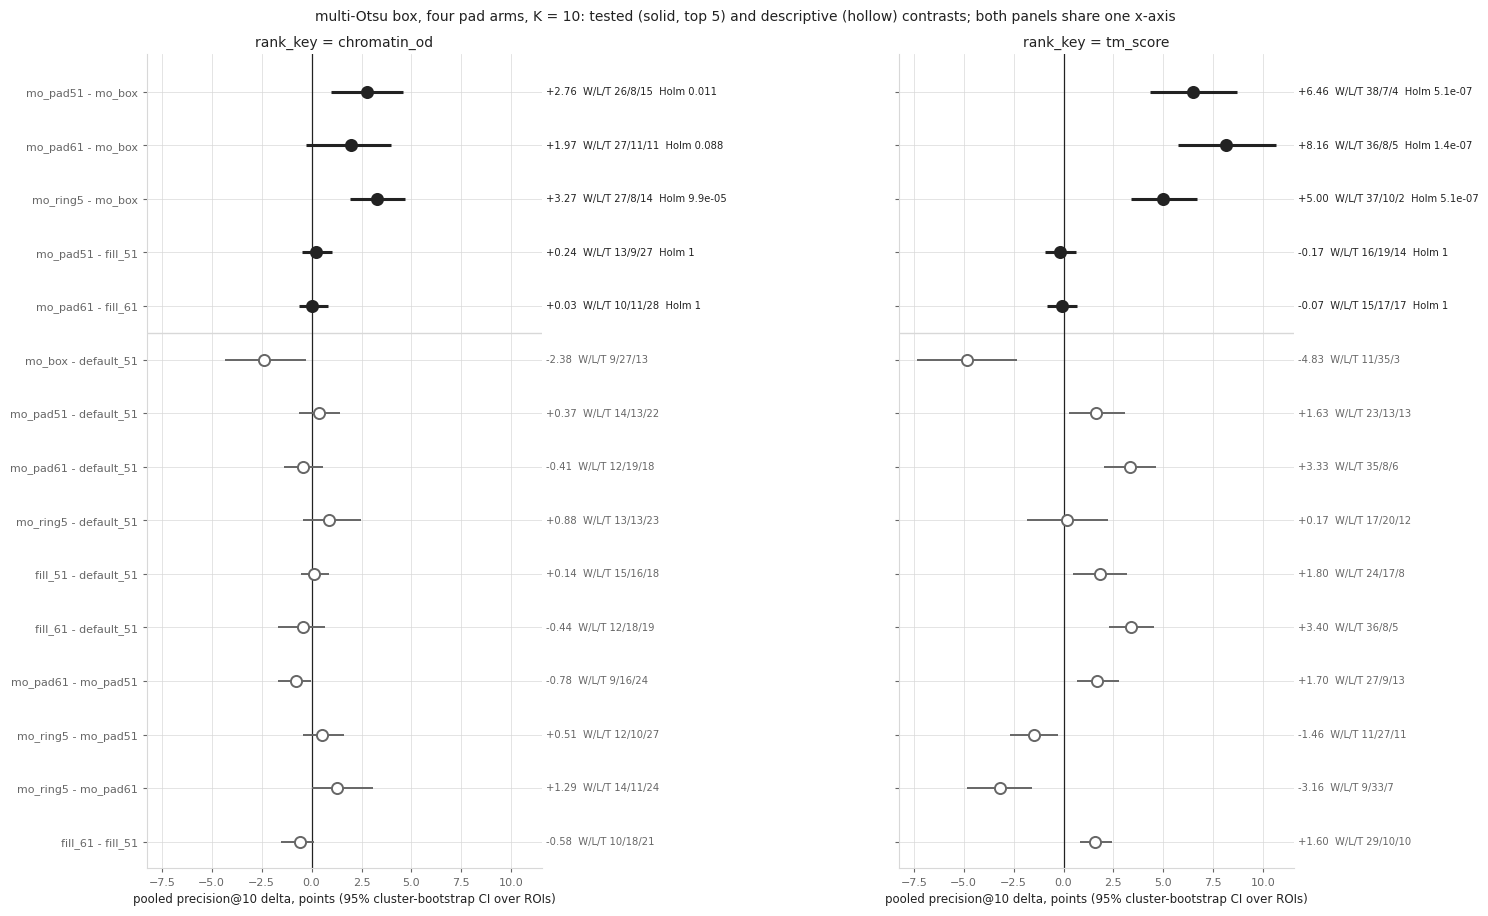

-> mopad_contrasts.png  (shared x-axis; the data span -7.35 to +10.65 points over both panels)


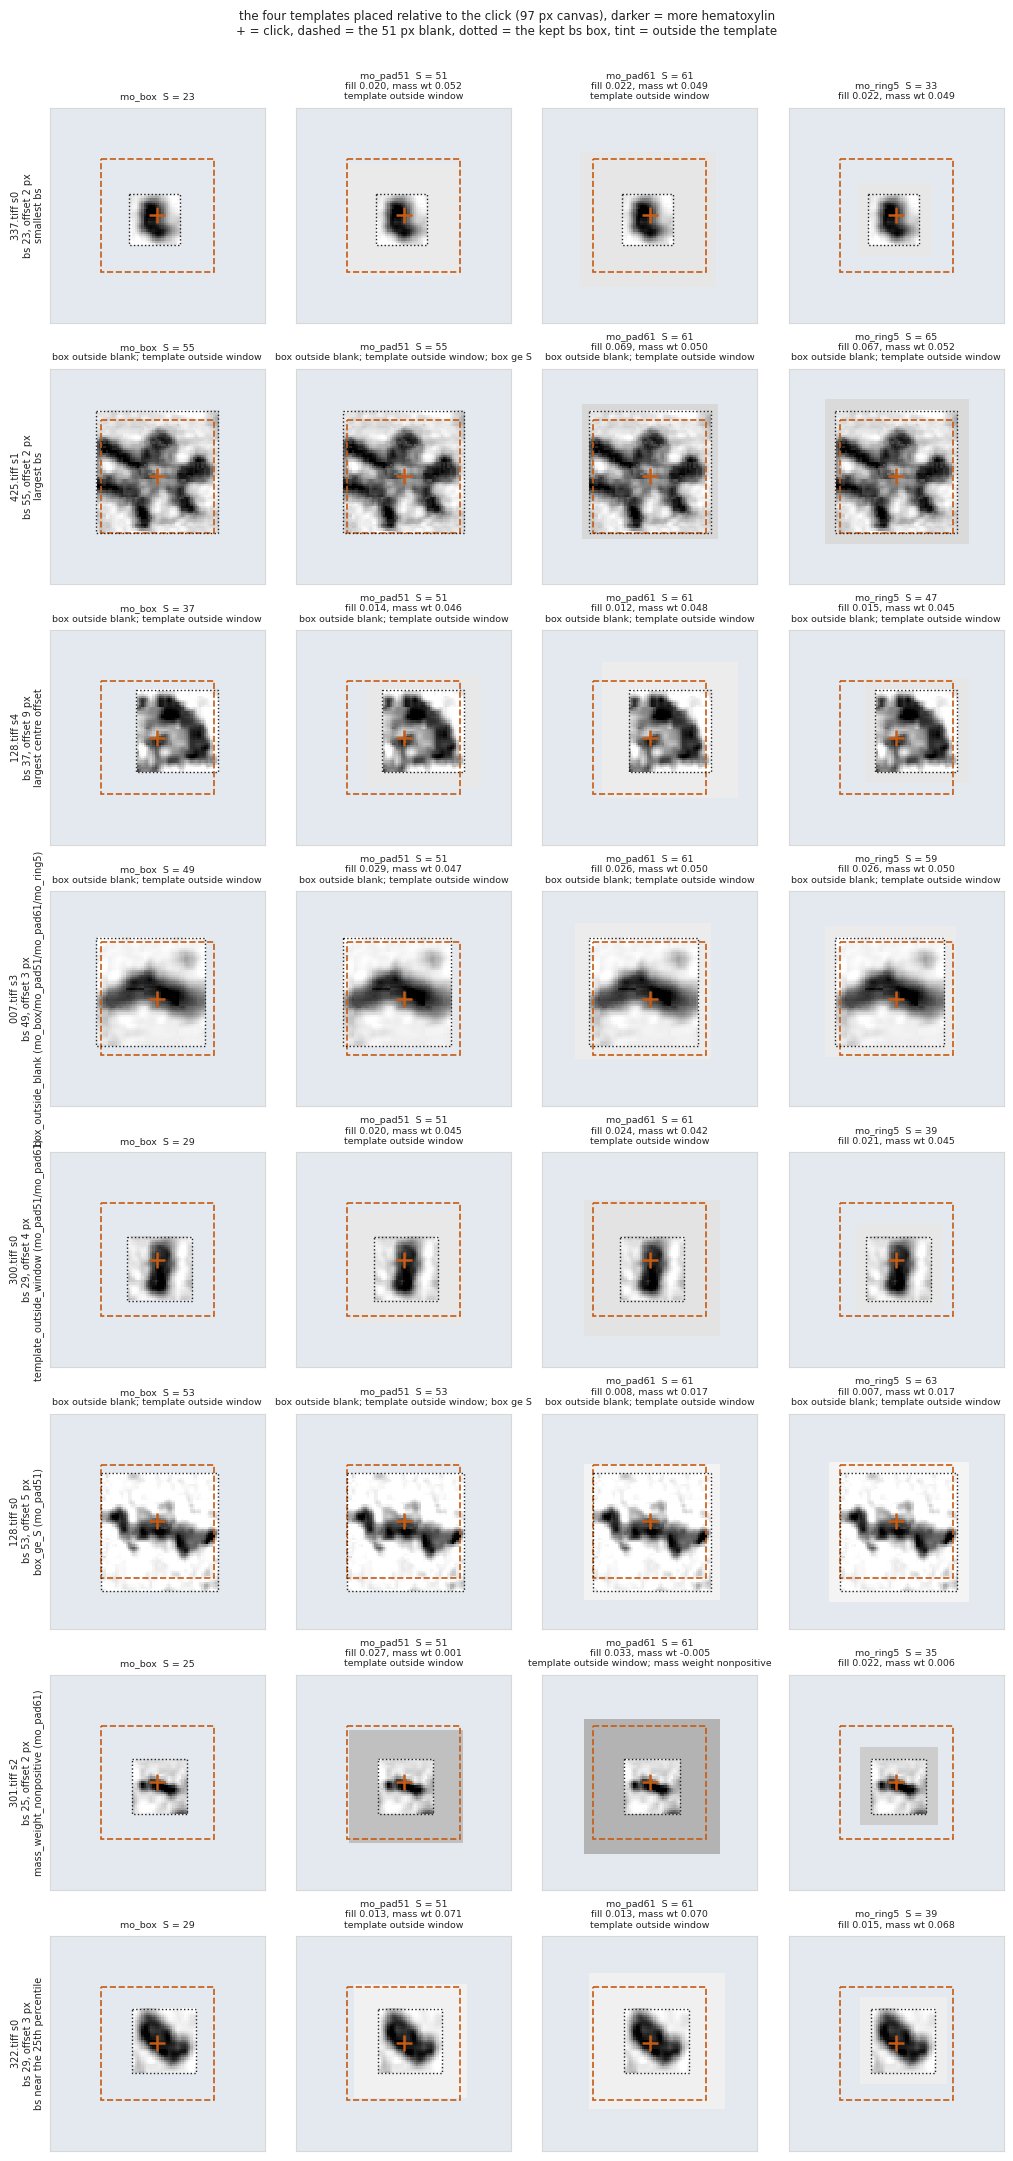

-> mopad_templates.png  (8 clicks: 337.tiff s0 = smallest bs; 425.tiff s1 = largest bs; 128.tiff s4 = largest centre offset; 007.tiff s3 = box_outside_blank (mo_box/mo_pad51/mo_pad61/mo_ring5); 300.tiff s0 = template_outside_window (mo_pad51/mo_pad61); 128.tiff s0 = box_ge_S (mo_pad51); 301.tiff s2 = mass_weight_nonpositive (mo_pad61); 322.tiff s0 = bs near the 25th percentile)

notebook total: 70.0 min


In [15]:
INK, MUTED, GRID = '#222222', '#666666', '#d8d8d8'
ACCENT = '#c75b12'   # one overlay hue on the grey templates; the marks differ by line style too, never by colour alone


def recessive(ax):
    """
        Push an axes' frame and grid behind the data, the house style for every panel here.

        ax (matplotlib.axes.Axes): the axes to restyle.

        Returns None.
    """
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=8, length=3)
    ax.grid(True, color=GRID, linewidth=0.6, alpha=0.8)
    ax.set_axisbelow(True)


# Figure 1 -- every K = 10 contrast on both axes, on ONE shared x-axis. Tested rows are solid with their Holm p; descriptive rows are hollow.
order = list(TESTED) + [c for c in CONTRASTS if c not in TEST_FAMILY]
k10 = DELTA_STATS[(DELTA_STATS['metric'] == 'tp_at_10') & (DELTA_STATS['version'] == 'recorded')]
fig, axes = plt.subplots(1, len(AXES), figsize=(7.5 * len(AXES), 0.5 * len(order) + 1.8), sharey=True, sharex=True)
for col, axis in enumerate(AXES):
    ax = axes[col]
    for j, name in enumerate(order):
        st = k10[(k10['rank_key'] == axis) & (k10['contrast'] == name)].iloc[0]
        tested = st['role'] == 'tested'
        ax.plot([100 * st['ci_low'], 100 * st['ci_high']], [j, j], color=INK if tested else MUTED, linewidth=2.2 if tested else 1.4, solid_capstyle='butt', zorder=3)
        ax.plot([100 * st['pooled_delta_precision']], [j], marker='o', ms=8, color=INK if tested else 'white', markeredgecolor=INK if tested else MUTED, markeredgewidth=1.4, zorder=4)
        note = f"{100 * st['pooled_delta_precision']:+.2f}  W/L/T {int(st['wins'])}/{int(st['losses'])}/{int(st['ties'])}" + (f"  Holm {st['holm_p']:.2g}" if tested else '')
        ax.annotate(note, xy=(1.01, j), xycoords=('axes fraction', 'data'), fontsize=7.2, color=INK if tested else MUTED, va='center', ha='left', annotation_clip=False)
    ax.axvline(0, color=INK, linewidth=0.9, zorder=2)
    ax.axhline(len(TESTED) - 0.5, color=GRID, linewidth=1.0, zorder=1)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order, fontsize=7.5, color=INK)
    ax.set_ylim(len(order) - 0.5, -0.7)
    ax.set_xlabel(f'pooled precision@{TEST_K} delta, points (95% cluster-bootstrap CI over ROIs)', fontsize=8.5, color=INK)
    ax.set_title(f'rank_key = {axis}', fontsize=10, color=INK)
    recessive(ax)
fig.suptitle(f'multi-Otsu box, four pad arms, K = {TEST_K}: tested (solid, top {len(TESTED)}) and descriptive (hollow) contrasts; both panels share one x-axis', fontsize=10, color=INK)
fig.tight_layout(w_pad=12.0)
fig.savefig(FIG_PATHS['contrasts'], dpi=130, bbox_inches='tight')
plt.show()
plt.close(fig)
lo_all, hi_all = 100 * k10['ci_low'].min(), 100 * k10['ci_high'].max()
print(f"-> {FIG_PATHS['contrasts']}  (shared x-axis; the data span {lo_all:+.2f} to {hi_all:+.2f} points over both panels)")

# Figure 2 -- the four templates for 8 clicks, each placed where it sits relative to the click, with the click (+) and the 51 px blank (dashed)
clk_tab = TA[TA['condition'] == 'mo_box'].reset_index(drop=True)
picks = []


def pick(idx, why):
    """
        Add one click to the gallery unless it is already in it.

        idx (int): a row index of clk_tab.
        why (str): the reason it is shown.

        Returns None.
    """
    key = (clk_tab.loc[idx, 'file_name'], int(clk_tab.loc[idx, 'seed_index']))
    if key not in [p[0] for p in picks] and len(picks) < 8:
        picks.append((key, why))


pick(int(clk_tab['bs'].astype(int).idxmin()), 'smallest bs')
pick(int(clk_tab['bs'].astype(int).idxmax()), 'largest bs')
pick(int(clk_tab['offset_px'].idxmax()), 'largest centre offset')
for flag in FIRED:
    hit = TA[TA[flag]]
    keys = list(zip(hit['file_name'], hit['seed_index'].astype(int)))
    fresh = [k for k in keys if k not in [p[0] for p in picks]]
    if fresh:
        pick(int(clk_tab.index[(clk_tab['file_name'] == fresh[0][0]) & (clk_tab['seed_index'] == fresh[0][1])][0]), f'{flag} ({"/".join(sorted(set(hit.loc[(hit["file_name"] == fresh[0][0]) & (hit["seed_index"] == fresh[0][1]), "condition"])))})')
for q in (0.25, 0.5, 0.75, 0.1, 0.9):
    target = clk_tab['bs'].astype(int).quantile(q)
    for idx in (clk_tab['bs'].astype(int) - target).abs().sort_values(kind='stable').index:
        before = len(picks)
        pick(int(idx), f'bs near the {int(100 * q)}th percentile')
        if len(picks) > before or len(picks) == 8:
            break
CANVAS = 97
half_c = CANVAS // 2
fig, axes = plt.subplots(len(picks), len(ARMS), figsize=(2.6 * len(ARMS), 2.75 * len(picks)))
axes = np.atleast_2d(axes)
for row_i, ((fn, s), why) in enumerate(picks):
    c = clk_tab[(clk_tab['file_name'] == fn) & (clk_tab['seed_index'] == s)].iloc[0]
    ix, iy = int(round(c['click_cx'])), int(round(c['click_cy']))
    bs, tcx, tcy = int(c['bs']), int(c['tcx']), int(c['tcy'])
    vals = np.concatenate([GALLERY[(fn, s)][arm].ravel() for arm in ARMS])
    vmin, vmax = np.percentile(vals, [1, 99])
    for col, arm in enumerate(ARMS):
        ax = axes[row_i, col]
        T = GALLERY[(fn, s)][arm]
        S = T.shape[0]
        canvas = np.full((CANVAS, CANVAS), np.nan, dtype=np.float32)
        y0, x0 = half_c + (tcy - iy) - S // 2, half_c + (tcx - ix) - S // 2
        assert y0 >= 0 and x0 >= 0 and y0 + S <= CANVAS and x0 + S <= CANVAS, 'the gallery canvas is too small'
        canvas[y0:y0 + S, x0:x0 + S] = T
        cmap = plt.get_cmap('gray_r').copy()
        cmap.set_bad('#e4e9ef')
        ax.imshow(canvas, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.add_patch(plt.Rectangle((half_c - HALF_BLANK - 0.5, half_c - HALF_BLANK - 0.5), BLANK_SIZE, BLANK_SIZE, fill=False, edgecolor=ACCENT, linestyle='--', linewidth=1.2))
        bh = (bs - 1) // 2
        ax.add_patch(plt.Rectangle((half_c + (tcx - ix) - bh - 0.5, half_c + (tcy - iy) - bh - 0.5), bs, bs, fill=False, edgecolor=INK, linestyle=':', linewidth=1.0))
        ax.plot(half_c, half_c, marker='+', color=ACCENT, ms=11, mew=1.8)
        r_ = TA[(TA['file_name'] == fn) & (TA['seed_index'] == s) & (TA['condition'] == arm)].iloc[0]
        flags_on = [f.replace('_', ' ') for f in FLAGS if r_[f]]
        extra = '' if np.isnan(r_['mass_weight']) else f"\nfill {r_['fill_value']:.3f}, mass wt {r_['mass_weight']:.3f}"
        ax.set_title(f'{arm}  S = {S}{extra}' + (f"\n{'; '.join(flags_on)}" if flags_on else ''), fontsize=6.8, color=INK)
        ax.set_xticks([])
        ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_color(GRID)
        if col == 0:
            ax.set_ylabel(f'{fn} s{s}\nbs {bs}, offset {int(c["offset_cheb_px"])} px\n{why}', fontsize=7, color=INK)
fig.suptitle(f'the four templates placed relative to the click ({CANVAS} px canvas), darker = more hematoxylin\n+ = click, dashed = the 51 px blank, dotted = the kept bs box, tint = outside the template', fontsize=8.5, color=INK)
fig.tight_layout(rect=(0, 0, 1, 1 - 0.5 / len(picks) / 2.75))
fig.savefig(FIG_PATHS['templates'], dpi=120, bbox_inches='tight')
plt.show()
plt.close(fig)
print(f"-> {FIG_PATHS['templates']}  ({len(picks)} clicks: " + '; '.join(f'{fn} s{s} = {why}' for (fn, s), why in picks) + ')')
print(f'\nnotebook total: {(time.time() - NB_T0) / 60:.1f} min')

## Reading the result

**Every gate held.**
- The configuration matches `midog_utils.production`.
- Before any search, the statistics code reproduced all 10 recorded fill-geometry `delta_stats` rows. `pair_stats_clicks` equals `pair_stats` bit for bit on them.
- `refine_template_box` accepted **294 / 294 clicks: 0 refusals**, so no click was dropped from any arm or reference.
- The tripwire reproduced 19 / 19 adoption clicks exactly (`accepted`, `base_size_px`, `center_x`, `center_y`). `pad_px == 2` held on every ROI (asserted).
- The parity gate held on 48 / 48 (click, arm, axis) rows of `default_51` and `fill_61`, with top-30 `od` bit-exact on 1440 / 1440 at the 25 px `od` pad the main loop uses.
- Asserts 1-4 held on all 1176 searches.
- The 6 `box_ge_S` searches reproduced `mo_box` exactly.
- `fill_61 - fill_51` on these clicks reproduces the window sweep's saved row on both axes, so the reference join is right.

The box: `bs` runs from 23 to 55 px, median 33. `bs >= 51` on 6 clicks. The selection was the base case on 259 clicks and the fallback on 35. The box centre sits a median 2.50 px from the click (max 9.66).

### The contamination rule did not fire

No arm has a self-match on either axis:
- no non-TP detection within 2 px of the template centre or of the click;
- not in any top 10, not in any top 30, and not anywhere in any arm's full detection list (`n_selfmatch_all` = 0);
- the same holds for the three references in their saved top 10 and top 30 (their full lists were not saved).

So all 10 tested contrasts are **clean** under the pre-registered rule. The self-match-dropped version equals the recorded one, and no worst case was needed. The two pre-registered worst-case extensions (the union neighbourhood and the two-ended bound) were therefore not exercised in the recorded run.

The near-seed diagnostic agrees: 0 non-TP top-10 detections within each click's reach, and 0 within the sweep's fixed 60 px, on every arm and both axes.

### The flags (reported, not lifted)

| flag | `mo_box` | `mo_pad51` | `mo_pad61` | `mo_ring5` |
|---|---|---|---|---|
| `box_outside_blank` | 14 | 14 | 14 | 14 |
| `template_outside_window` (informational) | 14 | 276 | 294 | 85 |
| `roi_edge_read` | 0 | 0 | 0 | 0 |
| `box_ge_S` | -- | 6 | 0 | -- |
| `mass_weight_nonpositive` | -- | 0 | **3** | 0 |

**Minimum mass weight `m_k - f`:** `mo_pad51` 0.00053, **`mo_pad61` -0.00503**, `mo_ring5` 0.00445. `mo_box` has no fill.

**Contrary to the prompt's expectation, the non-positive mass weight is on `mo_pad61`, not `mo_ring5`.** It fires on 3 clicks:
- `301.tiff` s2: -0.0050;
- `245.tiff` s2: -0.0004;
- `284.tiff` s3: -0.0012.

All three are small boxes (`bs` 25-33) in a 61 px window whose pad is, on average, as dark as the box itself. On these clicks the response at the template's own position is positive. No self-match followed, and none of the three is `box_outside_blank`.

**Flag-excluded reruns (descriptive).** Excluding any one of the four non-informational flags, or their union, leaves the D5 verdict of every tested contrast unchanged on both axes. Only one sign changes: `chromatin_od` `mo_pad61 - fill_61` goes from +0.03 to -0.10 without the `mass_weight_nonpositive` clicks, and to -0.07 without the union. Both versions are nulls. For example, with the union excluded (14-17 clicks):
- `tm_score`: `mo_pad61 - mo_box` is +8.41 pts [+5.82, +11.03], and `mo_pad51 - fill_51` is -0.11 [-0.93, +0.72];
- `chromatin_od`: `mo_pad61 - mo_box` stays not met (+2.09 [-0.33, +4.23]).

The `template_outside_window` rerun is uninformative by construction:
- In every `mo_pad61` contrast, no clicks remain.
- In the `mo_pad51` contrasts, 18 clicks in 15 ROIs remain.
- `mo_ring5 - mo_box`, excluding its 85 flagged clicks, still meets D5 on both axes: +4.88 [+2.86, +7.00] at `tm_score`, +4.21 [+2.38, +6.19] at `chromatin_od`.

### The 10 tests (K = 10, 49 ROIs, 294 clicks)

| axis | family | contrast | delta, pts | boot CI | t CI | W/L/T | nonzero | exact p | Holm | D5 |
|---|---|---|---|---|---|---|---|---|---|---|
| `tm_score` | pad | `mo_pad51 - mo_box` | **+6.46** | [+4.35, +8.67] | [+4.20, +8.72] | 38/7/4 | 45 | 2.554e-07 | 5.108e-07 | **met** (38/49) |
| `tm_score` | pad | `mo_pad61 - mo_box` | **+8.16** | [+5.71, +10.65] | [+5.57, +10.76] | 36/8/5 | 44 | 4.759e-08 | 1.428e-07 | **met** (36/49) |
| `tm_score` | pad | `mo_ring5 - mo_box` | **+5.00** | [+3.37, +6.67] | [+3.26, +6.74] | 37/10/2 | 47 | 4.328e-07 | 5.108e-07 | **met** (37/49) |
| `tm_score` | vs_incumbent | `mo_pad51 - fill_51` | -0.17 | [-0.95, +0.65] | [-0.99, +0.65] | 16/19/14 | 35 | 0.7407 | 1 | not met |
| `tm_score` | vs_incumbent | `mo_pad61 - fill_61` | -0.07 | [-0.82, +0.68] | [-0.84, +0.70] | 15/17/17 | 32 | 0.9296 | 1 | not met |
| `chromatin_od` | pad | `mo_pad51 - mo_box` | **+2.76** | [+0.95, +4.56] | [+0.86, +4.65] | 26/8/15 | 34 | 0.005258 | 0.01052 | **met** (26/49) |
| `chromatin_od` | pad | `mo_pad61 - mo_box` | +1.97 | [-0.31, +3.98] | [-0.28, +4.23] | 27/11/11 | 38 | 0.08761 | 0.08761 | not met |
| `chromatin_od` | pad | `mo_ring5 - mo_box` | **+3.27** | [+1.90, +4.66] | [+1.82, +4.71] | 27/8/14 | 35 | 3.292e-05 | 9.876e-05 | **met** (27/49) |
| `chromatin_od` | vs_incumbent | `mo_pad51 - fill_51` | +0.24 | [-0.48, +1.02] | [-0.54, +1.01] | 13/9/27 | 22 | 0.6156 | 1 | not met |
| `chromatin_od` | vs_incumbent | `mo_pad61 - fill_61` | +0.03 | [-0.61, +0.82] | [-0.71, +0.78] | 10/11/28 | 21 | 1 | 1 | not met |

No tested row is floor-blocked: the largest Holm-adjusted floor is 1.91e-06. All five CIs that exclude 0 do so on all 20 re-seeded bootstraps. The closest bound to 0 is +0.85 points, on `chromatin_od` `mo_pad51 - mo_box`.

**Padding the multi-Otsu box helps at `tm_score`, whichever pad is used.**
- Against the bare box, `mo_pad51` adds +6.46 points of precision@10, `mo_pad61` +8.16 and `mo_ring5` +5.00.
- All three clear Holm and meet D5; 36-38 of 49 ROIs improve and 7-10 lose.
- Pooled precision@10 goes from 0.4602 (`mo_box`) to 0.5102 (`mo_ring5`), 0.5248 (`mo_pad51`) and 0.5418 (`mo_pad61`).

**At `chromatin_od`, two of the three pads help.**
- `mo_pad51` gives +2.76 and `mo_ring5` +3.27; both meet D5.
- For `mo_pad61`, no gain is established: +1.97, CI [-0.31, +3.98], Holm 0.0876.
- With the edge band dropped, `mo_pad61 - mo_box` at `chromatin_od` is +2.69 [+0.85, +4.52]. That row is descriptive and changes no verdict.

The two axes are two outcomes. The `chromatin_od` results do not replicate the `tm_score` ones, and the `mo_pad61` null at `chromatin_od` does not cancel its `tm_score` gain.

**Against the incumbent at the same window side, no difference is detected on either axis.**
- `mo_pad51 - fill_51` is -0.17 [-0.95, +0.65] at `tm_score` and +0.24 [-0.48, +1.02] at `chromatin_od`.
- `mo_pad61 - fill_61` is -0.07 [-0.82, +0.68] and +0.03 [-0.61, +0.82].
- Pooled precision@10 at `tm_score` is 0.5248 against 0.5265 at 51, and 0.5418 against 0.5425 at 61.
- No equivalence is claimed; the CIs are the bound, about +/-1 point.
- This family moves three things at once: the kept region (the multi-Otsu box instead of the recorded Otsu rectangle), the centre (the box centre instead of the click) and the fill value. A null here is not attributed to any one of them, and neither would a difference have been.

### Descriptive: every arm minus `default_51` (no verdict)

| contrast | `tm_score` | `chromatin_od` |
|---|---|---|
| `mo_box - default_51` | -4.83 [-7.35, -2.35], 11/35/3 | -2.38 [-4.32, -0.31], 9/27/13 |
| `mo_pad51 - default_51` | +1.63 [+0.27, +3.10], 23/13/13 | +0.37 [-0.61, +1.43], 14/13/22 |
| `mo_pad61 - default_51` | +3.33 [+2.04, +4.63], 35/8/6 | -0.41 [-1.36, +0.58], 12/19/18 |
| `mo_ring5 - default_51` | +0.17 [-1.84, +2.24], 17/20/12 | +0.88 [-0.41, +2.48], 13/13/23 |
| `fill_51 - default_51` | +1.80 [+0.48, +3.20], 24/17/8 | +0.14 [-0.54, +0.88], 15/16/18 |
| `fill_61 - default_51` | +3.40 [+2.28, +4.56], 36/8/5 | -0.44 [-1.67, +0.65], 12/18/19 |

**The unpadded box is worse than the untouched 51 px window**: -4.83 points at `tm_score` and -2.38 at `chromatin_od`. Much of the pad arms' tested gain is recovering that deficit. Padded to 51 or 61, the box lands about where the recorded fill template lands at the same side: +1.63 / +3.33 against +1.80 / +3.40 at `tm_score`.

Between the pads (descriptive):
- **At `tm_score`:** `mo_pad61 - mo_pad51` +1.70 [+0.68, +2.76], `mo_ring5 - mo_pad51` -1.46 [-2.69, -0.27], `mo_ring5 - mo_pad61` -3.16 [-4.83, -1.60].
- **At `chromatin_od`:** `mo_pad61 - mo_pad51` -0.78 [-1.70, -0.03], `mo_ring5 - mo_pad51` +0.51 [-0.41, +1.60], `mo_ring5 - mo_pad61` +1.29 [+0.00, +3.06].

The axes disagree on which pad is best, and none of these rows was tested.

### Other diagnostics

- **`MAX_PEAKS`** binds on every row of every arm (`n_peaks` = 100 throughout). Mean NMS suppression per search is 0.918 to 1.72.
- **ROI edge**, the share of top-10 slots in the 35 px band:
  - `chromatin_od`: 5.41% (`mo_box`) to 6.46% (`mo_pad61`), against 6.02-6.56% for the references;
  - `tm_score`: 2.65-3.06%, against 3.10-3.30%;
  - dropping the band leaves the sign of every tested contrast unchanged.
- **Runtime:** the search loop took 64.2 min for 1176 searches, and the notebook 70.0 min in total.

### What this means

- **At `tm_score`, every pad tested beats the bare multi-Otsu box:** +5.00 to +8.16 points of precision@10, Holm <= 5.1e-07, D5 met for `mo_pad51`, `mo_pad61` and `mo_ring5`. Descriptively, with no verdict, the bare box sits 4.83 points below the untouched 51 px window.
- **At `chromatin_od`, `mo_pad51` and `mo_ring5` beat the bare box and meet D5; for `mo_pad61` no gain is established.**
- **The new box, padded, does not detectably beat the recorded Otsu-rectangle fill at the same window side on either axis.** The CIs bound the difference to about +/-1 point. Because the kept region, the centre and the fill all change together in that comparison, this does not show that the box and the rectangle are interchangeable.
- **Which pad to adopt is not answered here.** The pad-versus-pad rows are descriptive and point different ways on the two axes.
- **Scope:** all of this is on the 294 clicks drawn under the old Otsu joint gate, so it holds for clicks that both old Otsu gates accept.

### Standing caveats

- The 294 clicks were drawn under the old Otsu joint gate, so every click is one that both old Otsu gates accept. A click the new method would face in production may not be.
- Only K = 10 was tested. K = 20 / 30, the edge-band column, the flag-excluded reruns and the self-match versions are descriptive.
- The blank stays 51 x 51 on the click for every arm. This departs from D11, which blanks the template's own footprint at the template centre. On the 14 `box_outside_blank` clicks, part of the kept box is unblanked image. No self-match was found there, and excluding them changes no verdict.
- `mo_pad61` carries 3 non-positive mass weights (minimum -0.00503). Reported, not lifted; excluding them changes no verdict.
- No domain analysis was run.